# ビジネス部門に提示するためのベイジアンネットワーク検証

# R / bnlearn：出力の意味と妥当性を検証する

**実行環境：conda `bn`、カーネル `R (bn)`。分析はRとbnlearnのみで行い、pgmpyは使用しません。**

目的は正解構造や因果関係の証明ではなく、①構造がデータを説明できるか、②確率を十分な精度で推定できるか、③項目間の関係が取り直しても残るか、を区別して検証することです。

既存の5列の人工データ（Cloudy=曇り、Rain=雨、Sprinkler=散水、WetGrass=芝生の濡れ、Slippery=滑りやすい状態、いずれも0/1）を使います。Slipperyは事故実績ではありません。開発標本2,400行、過去使用済みの評価標本2,000行。新しい独立検証や実業務の成果とは呼びません。

## 結論：数値の種類によって「妥当」の意味が違う

| 指標 | 良い方向／基準点 | どの程度なら妥当か |
|---|---|---|
| bnlearnのBIC・BDeu | **高い**ほど相対的に良い | 絶対的合格点なし。同じ変数・標本・スコア設定で比較し、CVを併用 |
| 全変数の平均負の対数尤度（joint NLL） | **低い**ほど良い | 独立モデルなどの基準より改善。値の絶対水準は変数数・状態数・分布に依存 |
| 目的変数のLog loss | **低い**ほど良い、0は完全予測 | 発生率だけの基準との改善幅を評価。実務上の最小差は業務側で設定 |
| Brier score（二値） | **低い**ほど良い、0は完全、範囲0〜1 | 0.25は常に0.5を予測した場合の値で、一般的な合格境界ではない |
| Brier skill | **高い**ほど良い、0は基準同等、1は完全 | >0は指定した基準より良いだけで実用性の保証ではない |
| CPTの確率 | 高い／低い自体に良し悪しなし | 0〜1・和1が必須。件数と区間幅、予測性能、事前感度を確認 |
| CPTの事後区間幅 | 同条件なら**狭い**ほど精密 | 本例の幅0.20は暫定設定。求める判断精度から設定し直す |
| Bootstrap strength | **高い**ほど再出現が安定 | 公式の一律合格点なし。自動境界、0.70/0.85/0.95、乱数・手法間で確認 |
| direction | 0.5から離れるほど一方向の支持 | 0.5は方向不確定。1が「ネットワークとして良い」わけではない |
| 辺削除時のΔBIC | **より負**なら辺のスコア寄与が大きい | 0は改善なし。負だから必ず重要とはせず、再標本化と併用 |
| 相互情報量・CramérのV | **高い**ほど関連が大きい | 普遍的な弱／中／強の境界を設定しない。尺度・分布・目的に依存 |
| 多重性調整済みp値 | **小さい**ほど独立仮説に反する証拠 | 0.05は慣用水準で、効果の大きさや実務妥当性の合格点ではない |

**「数学的な必須条件」「公式実装の仕様」「本例の暫定設定」を分けます。** 妥当性を一つの数値で自動合格にしません。各節のMarkdownには出典・出力列の意味・判断例・繰り返しの必要性を記載しています。


**p値の表記**：小さいp値は有効桁で表示します。`0*`はソフトウェアの返した原値0を表し、数学的に確率がゼロと解釈しません。Monte Carlo検定の有限回数や極小値の数値分解能に注意し、細かな順位を主張しないでください。

## 先に合意すること：検定を増やすより、主張と根拠を対応させる

目的は **構造・条件付き確率・エッジの強さを、どこまで信頼して読めるか説明すること**。因果効果やTrueの再現は評価対象外です。必要な確認事項を広く扱いますが、すべての業界に共通する「この検定に通れば提示してよい」という規則はありません。

### 参照する考え方と、その位置付け
- [ASAのp値に関する声明](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf)：統計的有意性だけで判断せず、効果量、設計、報告の透明性を併せて考えるための原則です。
- [NIST AI RMFのMEASURE](https://airc.nist.gov/airmf-resources/airmf/5-sec-core/)：妥当性・信頼性、評価、記録を用途に合わせて整える参考枠組みです。BN専用の義務的認証や数値基準ではありません。
- [bnlearn score](https://www.bnlearn.com/documentation/man/score.html)、[エッジ強度](https://www.bnlearn.com/documentation/man/arc.strength.html)、[条件付き独立性検定](https://www.bnlearn.com/documentation/man/ci.test.html)：計算の定義は使用ソフトウェアの仕様で確認します。
- [Rの多重比較補正](https://search.r-project.org/R/refmans/stats/html/p.adjust.html)：今回は依存のある検定も含むためHolm補正を用います。FDRを目的にBH/BYを用いる場合とは誤りの制御対象が異なります。

### 3種類の「妥当」を混同しない
| 段階 | 例 | 今回の位置付け |
|---|---|---|
| 計算として成立 | CPTの確率和が1、欠損や不正値がない | 必須の数値検査 |
| データに統計的支持がある | 再標本化でも残る、未使用foldで説明力がある、区間が狭い | 人工データ内で検証 |
| 業務で採用できる | 必要精度・対象範囲・取得時点・費用・損失・説明責任を満たす | 実条件がないため未判定 |

### 事前に設定する判断設計
| 項目 | 本Notebookの設定 | 実業務で決めること |
|---|---|---|
| 分析単位 | 独立行を仮定した人工観測 | 顧客、施設、日等。重複・相関をどう扱うか |
| 主評価 | 全変数の平均負の対数尤度、独立モデルとの差 | 業務の説明目的に合う指標と比較相手 |
| 副評価 | Slippery予測、確率精度、エッジ安定性 | 優先する誤り、少数群、利用時点 |
| 許容精度 | CPT幅0.20、MC半幅0.02は例示 | 最小実務改善幅、許容確率誤差 |
| 検定 | 明記した検定族ごとにHolm、探索水準0.05 | 仮説・族・検出したい最小差・採用条件 |
| データ利用 | 開発2,400行、過去使用済み評価2,000行 | 最終判断には未使用の別期間・施設の標本 |

過去の結果を見ているので、これらを正式な事前登録や確証的検証とは呼びません。全試行と不支持の結果も保存します。


## 検証の全体地図：実施・条件付き・未実施

| 観点 | 必要な検証／資料 | 今回 |
|---|---|---|
| 業務目的 | 何を説明し、何を決めるか、利用しない用途 | 教材として定義。実採用目的は未合意 |
| 代表性 | 母集団、抽出方法、欠落者、回答偏り | 人工データ。実母集団は未検証 |
| 観測単位・依存 | ID重複、施設・時系列相関 | メタデータなし。実務では群／時系列分割 |
| 品質・測定 | 欠損率、定義、入力範囲、再測定一致 | 範囲・欠損は確認。測定信頼性は未検証 |
| 前処理 | 欠損機構、離散化、外れ値、データ漏洩 | 完全二値のため補完・離散化不要。実データではfold内で実施 |
| 構造探索 | 複数探索法、スコア、親数制限、同値性 | HC/Tabu/MMHC等、BIC/BDeu。親数3は固定で感度未検証 |
| 選択の楽観性 | 選択を含む評価、候補の全記録 | 反復CV＋外側5/内側3のネストCV |
| 独立性の説明 | DAGが表す条件付き独立の食い違い | 過去使用済み評価データで探索的検定 |
| パラメータ | 正規化、支持件数、ゼロ、区間、事前依存 | MLE・ISS=1/10/100、信用区間、再学習区間 |
| 全体適合 | 周辺だけでなく組合せの頻度・残差 | 固定モデルのシミュレーション診断 |
| 関係の強さ | 出現率、情報量、削除時スコア、条件付き検定 | 複数の根拠を併記。意味の違いを説明 |
| 多重性 | 検定族、補正、探索と確証の区別 | 無条件10組、条件付き検定群、分布差5項目を別族と明記 |
| 検出力・必要標本 | 最小差と許容誤差、希少条件の件数 | 精度・学習曲線を提示。最小差未定のため事前パワー設計未実施 |
| 校正・比較 | 単純基準との差、確率と実績の一致 | NLL/Brier/校正。業務費用に基づく閾値は未設定 |
| 頑健性 | 乱数、探索法、標本数、事前分布 | 実行。変数定義・測定誤差・欠損機構の感度は未実施 |
| 部分集団 | 件数と性能・誤りの偏り | Rain/Cloudyの例。顧客層・施設・公平性の検証ではない |
| 外部妥当性 | 新期間・施設・独立分析者による確認 | 未実施。再実行や別seedで代替しない |
| 再現性 | コード、データ指紋、seed、環境、実行結果 | 保存 |
| 提示品質 | 主張と図表の対応、制約、反論への備え | 根拠台帳とスライド構成をNotebook内に作成 |
| 運用・承認 | 更新頻度、変化検知、停止基準、担当者承認 | 手順を記載、実運用・承認は未実施 |

この一覧は本課題の確認範囲であり、業界固有の規制・プライバシー・品質規格を網羅した適合証明ではありません。実データでは該当項目を追加してください。


## 1. 環境・設定・データ品質

### 出力の意味
`state1/state0`は状態別の件数、missingは欠損数です。少ない状態や親の組合せがあると推定が不安定になります。現在のプログラムは欠損なしの二値データ用です。実データの欠損を0に置き換えず、別途処理方針を決めてください。

### 設定と判断
CVは5分割×10回、Bootstrapは各手法1,000回×3seed。CPTの信用区間幅0.20、Monte Carlo半幅0.02は**説明用の設定**で、公的な合格基準ではありません。設定は最初のCONFIGで変更可能です。実業務の最小改善幅は設定していないため採用可否は保留します。重複する0/1の組合せは別の観測として起こるので自動削除しません。独立行の仮定は実データで別途確認してください。

In [1]:
library(bnlearn)
stopifnot(grepl('/envs/bn/',R.home(),fixed=TRUE))
options(repr.plot.width=14,repr.plot.height=5)
CONFIG<-list(cv_runs=10,cv_folds=5,bootstrap_R=1000,bootstrap_seeds=c(101,202,303),candidate_thresholds=c(.70,.85,.95),probability_width=.20,mc_halfwidth=.02,split_seed=42)
set.seed(CONFIG$split_seed)
read_data<-function(p){d<-read.csv(p);stopifnot(!anyNA(d),all(vapply(d,function(x)all(x %in% c(0,1)),logical(1))));d[]<-lapply(d,factor,levels=c(0,1));d}
dev<-read_data('data/develop.csv');evaluation<-read_data('data/validation.csv');target<-'Slippery'
md_table<-function(d){x<-d;for(k in names(x))if(is.numeric(x[[k]])){if(grepl('(^p$|^p_|_p$)',k))x[[k]]<-ifelse(x[[k]]==0,'0*',formatC(x[[k]],digits=3,format='g'))else x[[k]]<-formatC(x[[k]],digits=4,format='f')};paste(c(paste0('| ',paste(names(x),collapse=' | '),' |'),paste0('| ',paste(rep('---',ncol(x)),collapse=' | '),' |'),apply(x,1,function(r)paste0('| ',paste(r,collapse=' | '),' |'))),collapse='\n')}
show<-function(title,d,note=''){write.csv(d,paste0('results/',title,'.csv'),row.names=FALSE);IRdisplay::display_markdown(paste0('### ',title,'\n\n',md_table(d),'\n\n',note))}
quality<-data.frame(variable=names(dev),n=nrow(dev),missing=sapply(dev,function(x)sum(is.na(x))),state1=sapply(dev,function(x)sum(x=='1')),state0=sapply(dev,function(x)sum(x=='0')))
show('data_quality',quality);print(CONFIG);print(R.version.string);print(packageVersion('bnlearn'))

### data_quality

| variable | n | missing | state1 | state0 |
| --- | --- | --- | --- | --- |
| Cloudy | 2400.0000 | 0.0000 | 1215.0000 | 1185.0000 |
| Rain | 2400.0000 | 0.0000 | 1182.0000 | 1218.0000 |
| Sprinkler | 2400.0000 | 0.0000 | 724.0000 | 1676.0000 |
| WetGrass | 2400.0000 | 0.0000 | 1529.0000 | 871.0000 |
| Slippery | 2400.0000 | 0.0000 | 1400.0000 | 1000.0000 |



$cv_runs
[1] 10

$cv_folds
[1] 5

$bootstrap_R
[1] 1000

$bootstrap_seeds
[1] 101 202 303

$candidate_thresholds
[1] 0.70 0.85 0.95

$probability_width
[1] 0.2

$mc_halfwidth
[1] 0.02

$split_seed
[1] 42



[1] "R version 4.5.3 (2026-03-11)"


[1] ‘5.2.1’


## 2. 確率評価の関数と数学的な検査

### 確率計算は何を確認するか
bnlearnのCPTから全32状態の同時確率を計算し、周辺化します。これは5二値変数に適した厳密計算です。変数を増やすと2^pに増大するため大規模データでは別の推論法が必要です。

- `joint_NLL`：全5項目を同時に観測した確率の−logを1行で平均したもの。正の値が小さいほど予測分布が実績に近い。
- `target_NLL`：残り4項目を知ったときのSlipperyの予測損失。joint_NLLと数値を直接比較しません。
- `Brier`：予測確率と0/1実績の差の二乗平均。
- `valid_CPT`：有限値、0〜1、各親状態の確率和1を点検。

不可能だと予測した事象が実際に出たとき、対数損失は∞になります。小さな値への置換で隠しません。参考：[bnlearnパラメータ推定](https://www.bnlearn.com/examples/fit/)、[確率評価と校正](https://scikit-learn.org/stable/modules/calibration.html)。後者は指標の解説資料として参照するだけで、Pythonのライブラリは実行しません。

In [2]:
joint<-function(f){g<-expand.grid(setNames(rep(list(c('0','1')),length(f)),names(f)),stringsAsFactors=FALSE);p<-rep(1,nrow(g));for(v in names(f)){tab<-f[[v]]$prob;vs<-names(dimnames(tab));if(is.null(vs))vs<-v;p<-p*vapply(seq_len(nrow(g)),function(i)do.call('[',c(list(tab),as.list(g[i,vs,drop=FALSE]),list(drop=TRUE))),numeric(1))};stopifnot(all(is.finite(p)),abs(sum(p)-1)<1e-8);g$prob<-p;g}
query<-function(j,evidence=list()){ix<-rep(TRUE,nrow(j));for(v in names(evidence))ix<-ix & j[[v]]==as.character(evidence[[v]]);sum(j$prob[ix & j[[target]]=='1'])/sum(j$prob[ix])}
pred<-function(f,d){j<-joint(f);fs<-setdiff(names(f),target);keys<-apply(d[,fs,drop=FALSE],1,paste,collapse='|');u<-which(!duplicated(keys));values<-vapply(u,function(i)query(j,as.list(d[i,fs,drop=FALSE])),numeric(1));unname(setNames(values,keys[u])[keys])}
binary_loss<-function(y,p){out<-numeric(length(y));out[y==1]<- -log(p[y==1]);out[y==0]<- -log1p(-p[y==0]);out}
learn<-function(d,a)switch(a,HC_BIC=hc(d,score='bic',maxp=3),HC_BDeu=hc(d,score='bde',iss=10,maxp=3),Tabu=tabu(d,score='bic',maxp=3),MMHC=mmhc(d,restrict.args=list(test='mi',alpha=.01),maximize.args=list(score='bic',maxp=3)),Independent=empty.graph(names(d)))
fit_model<-function(g,d,method){if(method=='MLE')bn.fit(g,d,method='mle')else bn.fit(g,d,method='bayes',iss=as.numeric(sub('Bayes','',method)))}
valid_fit<-function(f)all(vapply(f,function(node){p<-node$prob;all(is.finite(p))&&all(p>=0)&&all(p<=1)&&all(abs(colSums(matrix(p,nrow=dim(p)[1]))-1)<1e-8)},logical(1)))
assess<-function(f,d){if(!valid_fit(f))return(c(joint_NLL=NA,target_NLL=NA,Brier=NA));p<-pred(f,d);y<-as.numeric(d[[target]]=='1');c(joint_NLL=-as.numeric(logLik(f,data=d))/nrow(d),target_NLL=mean(binary_loss(y,p)),Brier=mean((y-p)^2))}

## 3. 構造学習スコアの比較

### BICの符号に注意
bnlearnは `logLik − (log(n)/2)×自由パラメータ数` を返すため**高い方が良い**。一般の `−2logLik + log(n)×自由パラメータ数` とは−2倍の関係です。`BIC_bnlearn=-5000` と `-5100`なら前者が候補中では良い。

`gap_from_best_BIC`は最大BICとの差なので0が最良。`conventional_delta_BIC`はその2倍。同値な構造が同点になることがあり、最高点を得ても唯一の正しい構造とは言えません。BDeuの値はISSにも依存するため異なるISSでの差を同じ物差しとみなしません。訓練スコアだけで妥当性を確定せず次節の再標本化評価を使います。

**一律の合格値はありません。** 辺数も少ないほど常に良いわけではなく、適合と複雑さの兼ね合いです。出典：[bnlearn scoreの定義](https://www.bnlearn.com/documentation/man/score.html)。

In [3]:
algorithms<-c('HC_BIC','HC_BDeu','Tabu','MMHC','Independent')
nets<-setNames(lapply(algorithms,function(a)learn(dev,a)),algorithms)
scores<-do.call(rbind,lapply(algorithms,function(a){g<-nets[[a]];data.frame(algorithm=a,edges=nrow(arcs(g)),parameters=nparams(g,dev),BIC_bnlearn=score(g,dev,type='bic'),BDeu=score(g,dev,type='bde',iss=10))}))
scores$gap_from_best_BIC<-max(scores$BIC_bnlearn)-scores$BIC_bnlearn
scores$conventional_delta_BIC<-2*scores$gap_from_best_BIC
show('structure_scores',scores,'同じデータ・変数で比較。gap=0が候補中の最高。差が0でも唯一の構造とは限りません。常用BICの差はbnlearnの差の2倍です。')

### structure_scores

| algorithm | edges | parameters | BIC_bnlearn | BDeu | gap_from_best_BIC | conventional_delta_BIC |
| --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| HC_BDeu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Tabu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| MMHC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Independent | 0.0000 | 5.0000 | -8017.8055 | -8013.4292 | 2286.3437 | 4572.6875 |

同じデータ・変数で比較。gap=0が候補中の最高。差が0でも唯一の構造とは限りません。常用BICの差はbnlearnの差の2倍です。

## 4. 同じ分割での反復交差検証：構造とパラメータを検証

### なぜ繰り返すのか
1回だけでは分割が有利だった可能性が残るため、**5分割を10回**繰り返します。構造選択も各訓練fold内でやり直します。比較する手法は同じ分割を使います。HC/Tabu/MMHC等の構造比較はBayes10で統一し、パラメータ比較はHC_BICの同じfold内構造でMLE・ISS=1/10/100を比べます。

### 出力からの判断
`joint_NLL_mean`が低いモデルを候補としますが、同じ標本を使うrun間は独立ではありません。`min/max`は分割による範囲であり信頼区間ではなく、10回を独立サンプルとしたt検定もしません。`positive_run_fraction=1`は10回すべてで基準より良かったという記述にとどまります。

分割範囲が大きい／順位が変わる場合は20〜50回などに増やして安定を確認する方法がありますが、これは実務上の運用例で公式推奨回数ではありません。繰り返しで情報そのものは増えません。時系列・施設別データならその単位で分割してください。多数の候補から最良を選んで性能を主張する場合はネストしたCVか未使用の評価標本が別途必要です。

参考：[bnlearnのCV仕様](https://www.bnlearn.com/documentation/man/bn.cv.html)。今回は各候補を同じ分割で評価できるようRでループを書き、学習にはbnlearnを使っています。

In [4]:
specs<-rbind(data.frame(algorithm=algorithms,method='Bayes10'),data.frame(algorithm='HC_BIC',method=c('MLE','Bayes1','Bayes100')))
cv<-list();runs<-CONFIG$cv_runs;k<-CONFIG$cv_folds
for(run in seq_len(runs)){
 set.seed(500+run);fold<-integer(nrow(dev));for(z in levels(dev[[target]])){ix<-which(dev[[target]]==z);fold[ix]<-sample(rep(seq_len(k),length.out=length(ix)))}
 for(b in seq_len(k)){
  tr<-dev[fold!=b,];te<-dev[fold==b,];gg<-setNames(lapply(algorithms,function(a)learn(tr,a)),algorithms)
  for(i in seq_len(nrow(specs))){a<-specs$algorithm[i];m<-specs$method[i];f<-fit_model(gg[[a]],tr,m);sc<-assess(f,te);cv[[length(cv)+1]]<-data.frame(run=run,fold=b,n=nrow(te),algorithm=a,method=m,t(sc),valid_CPT=valid_fit(f))}
 }
 cat('CV run',run,'of',runs,'\n')
}
cv<-do.call(rbind,cv);write.csv(cv,'results/cv_all_folds.csv',row.names=FALSE)
run_scores<-aggregate(cbind(joint_NLL,target_NLL,Brier)~run+algorithm+method,data=cv,FUN=mean,na.action=na.pass)
cv_summary<-do.call(rbind,lapply(split(run_scores,interaction(run_scores$algorithm,run_scores$method,drop=TRUE)),function(x)data.frame(algorithm=x$algorithm[1],method=x$method[1],runs=nrow(x),joint_NLL_mean=mean(x$joint_NLL),joint_NLL_min=min(x$joint_NLL),joint_NLL_max=max(x$joint_NLL),target_NLL=mean(x$target_NLL),Brier=mean(x$Brier))))
show('repeated_CV',cv_summary,'低いほど良好。min/maxは分割を変えた10回の観測範囲で、95%信頼区間ではありません。各foldで構造から学習しています。MLEの無限大損失やNAは除外せず保存します。')
base<-run_scores[run_scores$algorithm=='Independent',c('run','joint_NLL')];names(base)[2]<-'baseline'
gain<-merge(run_scores,base,by='run');gain$improvement<-gain$baseline-gain$joint_NLL
stability_cv<-do.call(rbind,lapply(split(gain,interaction(gain$algorithm,gain$method,drop=TRUE)),function(x)data.frame(algorithm=x$algorithm[1],method=x$method[1],mean_improvement=mean(x$improvement),positive_run_fraction=mean(x$improvement>0))))
show('CV_improvement',stability_cv,'改善幅>0なら独立モデルより良好。10/10で改善しても確率100%の保証ではありません。繰り返しは同じ標本を共有するため独立試験ではありません。')

CV run 1 of 10 
CV run 2 of 10 
CV run 3 of 10 
CV run 4 of 10 
CV run 5 of 10 
CV run 6 of 10 
CV run 7 of 10 
CV run 8 of 10 
CV run 9 of 10 
CV run 10 of 10 


### repeated_CV

| algorithm | method | runs | joint_NLL_mean | joint_NLL_min | joint_NLL_max | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | Bayes1 | 10.0000 | 2.3754 | 2.3732 | 2.3767 | 0.3830 | 0.1120 |
| HC_BDeu | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| Independent | Bayes10 | 10.0000 | 3.3339 | 3.3331 | 3.3347 | 0.6792 | 0.2431 |
| MMHC | Bayes10 | 10.0000 | 2.3774 | 2.3733 | 2.3974 | 0.3830 | 0.1120 |
| Tabu | Bayes10 | 10.0000 | 2.3752 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes100 | 10.0000 | 2.3821 | 2.3804 | 2.3834 | 0.3845 | 0.1123 |
| HC_BIC | MLE | 10.0000 | 2.3754 | 2.3733 | 2.3768 | 0.3830 | 0.1120 |

低いほど良好。min/maxは分割を変えた10回の観測範囲で、95%信頼区間ではありません。各foldで構造から学習しています。MLEの無限大損失やNAは除外せず保存します。

### CV_improvement

| algorithm | method | mean_improvement | positive_run_fraction |
| --- | --- | --- | --- |
| HC_BIC | Bayes1 | 0.9586 | 1.0000 |
| HC_BDeu | Bayes10 | 0.9587 | 1.0000 |
| HC_BIC | Bayes10 | 0.9587 | 1.0000 |
| Independent | Bayes10 | 0.0000 | 0.0000 |
| MMHC | Bayes10 | 0.9566 | 1.0000 |
| Tabu | Bayes10 | 0.9588 | 1.0000 |
| HC_BIC | Bayes100 | 0.9519 | 1.0000 |
| HC_BIC | MLE | 0.9585 | 1.0000 |

改善幅>0なら独立モデルより良好。10/10で改善しても確率100%の保証ではありません。繰り返しは同じ標本を共有するため独立試験ではありません。

## 5. パラメータの妥当性：CPTの件数・事後区間・正規化

### CPTは何を意味するか
各行は `P(variable=1 | parentsの状態)`。`n_context`はその親状態の実測件数、eventsはそのうちvariable=1の件数。`MLE=events/n_context`。ベイズ推定は一様Dirichlet事前分布を加えます。親の組合せ数q、二値r=2なら各セルの事前量はISS/(2q)。ISSはノード全体の等価標本数で、各親状態に10件ずつ追加する意味ではありません。

### 妥当性の目安
確率が0.9だから良い／0.1だから悪い、ではありません。件数、予測性能、区間で確認します。`low/high`は**学習した構造を固定した**95%事後信用区間。構造選択・対象者の偏り・モデルの誤りは含みません。幅0.20は約±10ポイントの精度を求める今回の仮設定です。業務で±2ポイントが必要なら幅0.04等を検討します。

件数30や100だけで一律合格にしません。参考として二項比率p=0.5の正規近似では、95%半幅±0.10に約97件、±0.05に約385件が必要ですが、これは各親状態ごとの独立観測数の目安で、CPTの普遍的閾値ではありません。稀少事象では近似が悪いため実際の区間を確認します。

`n_context=0`はデータ根拠なし。ベイズ推定で数値を出せても事前分布頼みです。固定構造の解析的信用区間は反復不要。構造選択まで含めたい場合は構造からの再学習が必要です。参考：[bnlearnの推定例](https://www.bnlearn.com/examples/fit/)、[NIST：比率の区間](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm)。

In [5]:
chosen<-nets$HC_BIC;fitted<-fit_model(chosen,dev,'Bayes10');iss<-10
cpt<-list()
for(v in names(fitted)){
 pa<-parents(chosen,v);contexts<-if(length(pa))expand.grid(setNames(lapply(pa,function(p)levels(dev[[p]])),pa),stringsAsFactors=FALSE)else data.frame(dummy=1)
 q<-nrow(contexts)
 for(i in seq_len(q)){
  ix<-rep(TRUE,nrow(dev));if(length(pa))for(p in pa)ix<-ix & dev[[p]]==contexts[[p]][i]
  n<-sum(ix);yes<-sum(dev[[v]][ix]=='1');alpha<-iss/(2*q);post<-(yes+alpha)/(n+2*alpha)
  tab<-fitted[[v]]$prob;vs<-names(dimnames(tab));if(is.null(vs))vs<-v
  vals<-setNames(list('1'),v);for(p in pa)vals[[p]]<-contexts[[p]][i]
  actual<-do.call('[',c(list(tab),vals[vs],list(drop=TRUE)));stopifnot(abs(actual-post)<1e-10)
  lo<-qbeta(.025,yes+alpha,n-yes+alpha);hi<-qbeta(.975,yes+alpha,n-yes+alpha)
  cpt[[length(cpt)+1]]<-data.frame(variable=v,parents=if(length(pa))paste(paste(pa,contexts[i,pa],sep='='),collapse=',')else '(none)',n_context=n,events=yes,MLE=if(n)yes/n else NA,Bayes10=post,low=lo,high=hi,width=hi-lo,precision_check=if(hi-lo<=CONFIG$probability_width)'within_demo_tolerance'else 'needs_more_data')
 }
}
cpt<-do.call(rbind,cpt);show('CPT_precision',cpt,'low/highは構造とISSを固定したBeta事後95%信用区間。構造選択の不確実性は含みません。幅0.20は今回の仮の許容値であり公式合格基準ではありません。n_context=0ならデータ根拠がありません。')
checks<-do.call(rbind,lapply(c('MLE','Bayes1','Bayes10','Bayes100'),function(m){f<-fit_model(chosen,dev,m);data.frame(method=m,valid_CPT=valid_fit(f),zero_probabilities=sum(vapply(f,function(x)sum(x$prob==0,na.rm=TRUE),integer(1))),t(assess(f,evaluation)))}))
show('parameter_checks',checks,'確率は0〜1、親状態ごとの和=1が必須。計算誤差の許容1e-8は数値検査です。MLEで0になる場合、評価でその事象が出ると損失は無限大。ベイズ推定の非ゼロは十分なデータの証拠ではありません。')
prior_detail<-do.call(rbind,lapply(c(1,10,100),function(s){ff<-bn.fit(chosen,dev,method='bayes',iss=s);diff<-unlist(lapply(names(ff),function(v)as.numeric(ff[[v]]$prob)-as.numeric(fitted[[v]]$prob)));data.frame(ISS=s,max_CPT_change_from_ISS10=max(abs(diff)),mean_CPT_change=mean(abs(diff)),t(assess(ff,evaluation)))}))
show('prior_sensitivity',prior_detail,'構造を固定してISSだけを変えた検査。確率の変化は0〜1単位（0.01=1ポイント）。変化が小さければこの範囲の事前設定には頑健ですが、構造変更への頑健性を証明するものではありません。')


### CPT_precision

| variable | parents | n_context | events | MLE | Bayes10 | low | high | width | precision_check |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cloudy | (none) | 2400.0000 | 1215.0000 | 0.5062 | 0.5062 | 0.4863 | 0.5262 | 0.0399 | within_demo_tolerance |
| Rain | Cloudy=0 | 1185.0000 | 209.0000 | 0.1764 | 0.1777 | 0.1565 | 0.1999 | 0.0434 | within_demo_tolerance |
| Rain | Cloudy=1 | 1215.0000 | 973.0000 | 0.8008 | 0.7996 | 0.7767 | 0.8216 | 0.0449 | within_demo_tolerance |
| Sprinkler | Cloudy=0 | 1185.0000 | 612.0000 | 0.5165 | 0.5164 | 0.4880 | 0.5447 | 0.0568 | within_demo_tolerance |
| Sprinkler | Cloudy=1 | 1215.0000 | 112.0000 | 0.0922 | 0.0939 | 0.0781 | 0.1108 | 0.0327 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=0 | 695.0000 | 36.0000 | 0.0518 | 0.0534 | 0.0380 | 0.0713 | 0.0333 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=0 | 981.0000 | 879.0000 | 0.8960 | 0.8950 | 0.8751 | 0.9134 | 0.0383 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=1 | 523.0000 | 418.0000 | 0.7992 | 0.7978 | 0.7625 | 0.8310 | 0.0686 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=1 | 201.0000 | 196.0000 | 0.9751 | 0.9693 | 0.9416 | 0.9883 | 0.0467 | within_demo_tolerance |
| Slippery | WetGrass=0 | 871.0000 | 90.0000 | 0.1033 | 0.1056 | 0.0861 | 0.1268 | 0.0406 | within_demo_tolerance |
| Slippery | WetGrass=1 | 1529.0000 | 1310.0000 | 0.8568 | 0.8556 | 0.8376 | 0.8727 | 0.0352 | within_demo_tolerance |

low/highは構造とISSを固定したBeta事後95%信用区間。構造選択の不確実性は含みません。幅0.20は今回の仮の許容値であり公式合格基準ではありません。n_context=0ならデータ根拠がありません。

### parameter_checks

| method | valid_CPT | zero_probabilities | joint_NLL | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- |
| MLE | TRUE | 0.0000 | 2.3784 | 0.3999 | 0.1186 |
| Bayes1 | TRUE | 0.0000 | 2.3785 | 0.3999 | 0.1186 |
| Bayes10 | TRUE | 0.0000 | 2.3789 | 0.3998 | 0.1186 |
| Bayes100 | TRUE | 0.0000 | 2.3860 | 0.3999 | 0.1186 |

確率は0〜1、親状態ごとの和=1が必須。計算誤差の許容1e-8は数値検査です。MLEで0になる場合、評価でその事象が出ると損失は無限大。ベイズ推定の非ゼロは十分なデータの証拠ではありません。

### prior_sensitivity

| ISS | max_CPT_change_from_ISS10 | mean_CPT_change | joint_NLL | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- |
| 1.0000 | 0.0052 | 0.0014 | 2.3785 | 0.3999 | 0.1186 |
| 10.0000 | 0.0000 | 0.0000 | 2.3789 | 0.3998 | 0.1186 |
| 100.0000 | 0.0467 | 0.0135 | 2.3860 | 0.3999 | 0.1186 |

構造を固定してISSだけを変えた検査。確率の変化は0〜1単位（0.01=1ポイント）。変化が小さければこの範囲の事前設定には頑健ですが、構造変更への頑健性を証明するものではありません。

## 6. 関係の安定性：3つの乱数 × 各1000回 × 2手法

### strengthとdirectionを混同しない
strengthは同じサイズの標本を復元抽出して構造を再学習したとき、向きを無視した辺が出た割合です。directionは辺が存在する条件で表のfrom→toを支持する割合。CPDAGに変換するため同値な向きの不確実性を含みます。strength=0ならdirectionは定義できないためNAです。

### どの程度なら採用候補か
公式の一律基準はありません。`inclusion.threshold()`によるデータ依存の境界を併記し、0.70/0.85/0.95を超える辺がどう変わるかを示します。**0.85は便宜的な確認値で、有意水準15%でも真実確率85%でもありません。** 自動境界もFDRを保証しません。

1,000回を3つのseedで繰り返し、各手法3,000回分を集計します。`seed_range`は乱数別強度の最大−最小。HCとTabuで大きく違えば手法依存として保留します。`MC_low/high`は固定データに対する計算上の出現割合のWilson区間。母集団の辺が正しい確率ではありません。`robust_to_MC`はこの区間下限が指定境界を超えることだけを表します。

出典：[bnlearn アーク強度・自動閾値](https://www.bnlearn.com/documentation/man/arc.strength.html)、[NIST Wilson区間](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm)。

In [6]:
boots<-list();bootstrap_long<-list();thresholds<-list()
for(a in c('hc','tabu'))for(seed in CONFIG$bootstrap_seeds){
 set.seed(seed);b<-boot.strength(dev,R=CONFIG$bootstrap_R,algorithm=a,algorithm.args=list(score='bic',maxp=3),cpdag=TRUE)
 key<-paste(a,seed,sep='_');boots[[key]]<-b;z<-as.data.frame(b[b$from<b$to,]);z$algorithm<-a;z$seed<-seed;bootstrap_long[[key]]<-z
 thresholds[[key]]<-data.frame(algorithm=a,seed=seed,automatic_threshold=inclusion.threshold(b));cat('Bootstrap',key,'done\n')
}
bootstrap_long<-do.call(rbind,bootstrap_long);write.csv(bootstrap_long,'results/bootstrap_by_seed.csv',row.names=FALSE)
show('automatic_thresholds',do.call(rbind,thresholds),'inclusion.thresholdはデータから算出される境界で、FDR5%の保証や真の関係の確率ではありません。境界と同じ強度の辺は採用条件strength > thresholdを満たしません。')
edges<-do.call(rbind,lapply(split(bootstrap_long,interaction(bootstrap_long$algorithm,bootstrap_long$from,bootstrap_long$to,drop=TRUE)),function(z){p<-mean(z$strength);N<-CONFIG$bootstrap_R*nrow(z);zz<-1.96;center<-(p+zz^2/(2*N))/(1+zz^2/N);half<-zz*sqrt(p*(1-p)/N+zz^2/(4*N*N))/(1+zz^2/N);data.frame(algorithm=z$algorithm[1],from=z$from[1],to=z$to[1],strength=p,seed_range=diff(range(z$strength)),MC_low=center-half,MC_high=center+half,direction=if(sum(z$strength)>0)weighted.mean(z$direction,z$strength)else NA,MC_halfwidth=half)}))
show('edge_stability',edges,'MC区間は固定された入力標本からの反復回数の有限性だけを表します。母集団の真の辺への信頼区間ではありません。directionはこの表のfrom→toを支持する度合いで、0.5付近は方向不確定。')
threshold_sensitivity<-do.call(rbind,lapply(CONFIG$candidate_thresholds,function(t){x<-edges;x$threshold<-t;x$selected<-x$strength>t;x$robust_to_MC<-x$MC_low>t;x[,c('algorithm','from','to','threshold','strength','selected','robust_to_MC')]}))
show('threshold_sensitivity',threshold_sensitivity,'0.70/0.85/0.95は感度を見るための例示的境界です。0.85を普遍的な妥当性基準にはしません。MC下限が閾値を超える場合でも実務的重要性を意味しません。')

Bootstrap hc_101 done
Bootstrap hc_202 done
Bootstrap hc_303 done
Bootstrap tabu_101 done
Bootstrap tabu_202 done
Bootstrap tabu_303 done


### automatic_thresholds

| algorithm | seed | automatic_threshold |
| --- | --- | --- |
| hc | 101.0000 | 0.6370 |
| hc | 202.0000 | 0.6470 |
| hc | 303.0000 | 0.2860 |
| tabu | 101.0000 | 1.0000 |
| tabu | 202.0000 | 0.1290 |
| tabu | 303.0000 | 1.0000 |

inclusion.thresholdはデータから算出される境界で、FDR5%の保証や真の関係の確率ではありません。境界と同じ強度の辺は採用条件strength > thresholdを満たしません。

### edge_stability

| algorithm | from | to | strength | seed_range | MC_low | MC_high | direction | MC_halfwidth |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| hc | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Cloudy | Slippery | 0.0010 | 0.0020 | 0.0003 | 0.0029 | 0.8333 | 0.0013 |
| tabu | Cloudy | Slippery | 0.0017 | 0.0030 | 0.0007 | 0.0039 | 0.9000 | 0.0016 |
| hc | Rain | Slippery | 0.0030 | 0.0020 | 0.0016 | 0.0057 | 0.5556 | 0.0021 |
| tabu | Rain | Slippery | 0.0050 | 0.0030 | 0.0030 | 0.0082 | 0.9000 | 0.0026 |
| hc | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Rain | Sprinkler | 0.6457 | 0.0160 | 0.6284 | 0.6626 | 0.4987 | 0.0171 |
| tabu | Rain | Sprinkler | 0.1270 | 0.0060 | 0.1156 | 0.1394 | 0.5000 | 0.0119 |
| hc | Slippery | Sprinkler | 0.0047 | 0.0040 | 0.0028 | 0.0078 | 0.3929 | 0.0025 |
| tabu | Slippery | Sprinkler | 0.0067 | 0.0040 | 0.0043 | 0.0103 | 0.1250 | 0.0030 |
| hc | Cloudy | WetGrass | 0.2727 | 0.0270 | 0.2570 | 0.2889 | 0.5000 | 0.0159 |
| tabu | Cloudy | WetGrass | 0.0003 | 0.0010 | 0.0001 | 0.0019 | 0.5000 | 0.0009 |
| hc | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6763 | 0.0006 |
| tabu | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |
| hc | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.3228 | 0.0006 |
| tabu | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.0635 | 0.0006 |
| hc | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6770 | 0.0006 |
| tabu | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |

MC区間は固定された入力標本からの反復回数の有限性だけを表します。母集団の真の辺への信頼区間ではありません。directionはこの表のfrom→toを支持する度合いで、0.5付近は方向不確定。

### threshold_sensitivity

| algorithm | from | to | threshold | strength | selected | robust_to_MC |
| --- | --- | --- | --- | --- | --- | --- |
| hc | Cloudy | Rain | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Rain | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Slippery | 0.7000 | 0.0010 | FALSE | FALSE |
| tabu | Cloudy | Slippery | 0.7000 | 0.0017 | FALSE | FALSE |
| hc | Rain | Slippery | 0.7000 | 0.0030 | FALSE | FALSE |
| tabu | Rain | Slippery | 0.7000 | 0.0050 | FALSE | FALSE |
| hc | Cloudy | Sprinkler | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Sprinkler | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Rain | Sprinkler | 0.7000 | 0.6457 | FALSE | FALSE |
| tabu | Rain | Sprinkler | 0.7000 | 0.1270 | FALSE | FALSE |
| hc | Slippery | Sprinkler | 0.7000 | 0.0047 | FALSE | FALSE |
| tabu | Slippery | Sprinkler | 0.7000 | 0.0067 | FALSE | FALSE |
| hc | Cloudy | WetGrass | 0.7000 | 0.2727 | FALSE | FALSE |
| tabu | Cloudy | WetGrass | 0.7000 | 0.0003 | FALSE | FALSE |
| hc | Rain | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Rain | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Slippery | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Slippery | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Sprinkler | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| tabu | Sprinkler | WetGrass | 0.7000 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Rain | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Rain | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Slippery | 0.8500 | 0.0010 | FALSE | FALSE |
| tabu | Cloudy | Slippery | 0.8500 | 0.0017 | FALSE | FALSE |
| hc | Rain | Slippery | 0.8500 | 0.0030 | FALSE | FALSE |
| tabu | Rain | Slippery | 0.8500 | 0.0050 | FALSE | FALSE |
| hc | Cloudy | Sprinkler | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Sprinkler | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Rain | Sprinkler | 0.8500 | 0.6457 | FALSE | FALSE |
| tabu | Rain | Sprinkler | 0.8500 | 0.1270 | FALSE | FALSE |
| hc | Slippery | Sprinkler | 0.8500 | 0.0047 | FALSE | FALSE |
| tabu | Slippery | Sprinkler | 0.8500 | 0.0067 | FALSE | FALSE |
| hc | Cloudy | WetGrass | 0.8500 | 0.2727 | FALSE | FALSE |
| tabu | Cloudy | WetGrass | 0.8500 | 0.0003 | FALSE | FALSE |
| hc | Rain | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Rain | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Slippery | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Slippery | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Sprinkler | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| tabu | Sprinkler | WetGrass | 0.8500 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Rain | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Rain | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Cloudy | Slippery | 0.9500 | 0.0010 | FALSE | FALSE |
| tabu | Cloudy | Slippery | 0.9500 | 0.0017 | FALSE | FALSE |
| hc | Rain | Slippery | 0.9500 | 0.0030 | FALSE | FALSE |
| tabu | Rain | Slippery | 0.9500 | 0.0050 | FALSE | FALSE |
| hc | Cloudy | Sprinkler | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Cloudy | Sprinkler | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Rain | Sprinkler | 0.9500 | 0.6457 | FALSE | FALSE |
| tabu | Rain | Sprinkler | 0.9500 | 0.1270 | FALSE | FALSE |
| hc | Slippery | Sprinkler | 0.9500 | 0.0047 | FALSE | FALSE |
| tabu | Slippery | Sprinkler | 0.9500 | 0.0067 | FALSE | FALSE |
| hc | Cloudy | WetGrass | 0.9500 | 0.2727 | FALSE | FALSE |
| tabu | Cloudy | WetGrass | 0.9500 | 0.0003 | FALSE | FALSE |
| hc | Rain | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Rain | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Slippery | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Slippery | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| hc | Sprinkler | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |
| tabu | Sprinkler | WetGrass | 0.9500 | 1.0000 | TRUE | TRUE |

0.70/0.85/0.95は感度を見るための例示的境界です。0.85を普遍的な妥当性基準にはしません。MC下限が閾値を超える場合でも実務的重要性を意味しません。

## 7. 繰り返し回数はどの程度必要か

### 何回繰り返すべきか
Bootstrap出現率pのMonte Carlo標準誤差は独立な反復を仮定して `sqrt(p(1-p)/R)`。最大はp=0.5。おおよそR=200で95%半幅±6.9ポイント、R=1,000で±3.1ポイント、R=3,000で±1.8ポイントです。

**境界の付近だけなら追加反復が有効**ですが、ほぼ同じ結果を何度見ても元標本の偏りは消えません。今回の目標半幅±2ポイントは計算精度の暫定設定。2401回程度は近似計算から導く目安で、bnlearn公式の必要回数ではありません。

回数を増やしてもHCとTabuが異なる、対象期間で関係が変わる、希少状態が少ない場合は、手法・データ・仮説を見直します。既定seedを変えて都合のよい回だけを選ばないでください。

In [7]:
repeat_plan<-data.frame(bootstrap_R=c(200,500,1000,3000,10000),worst_MC_SE=sqrt(.25/c(200,500,1000,3000,10000)),approx_95_halfwidth=1.96*sqrt(.25/c(200,500,1000,3000,10000)))
show('repeat_precision',repeat_plan,'p=0.5の最悪条件による近似。例えば半幅±0.02を目標とするなら約2401回が目安です。これは再標本化の計算誤差で、データ不足を繰り返し回数で補えるわけではありません。')
need<-ceiling(.25*(1.96/CONFIG$mc_halfwidth)^2);print(need)
show('repeat_status',data.frame(total_per_algorithm=CONFIG$bootstrap_R*length(CONFIG$bootstrap_seeds),max_MC_halfwidth=max(edges$MC_halfwidth),target_halfwidth=CONFIG$mc_halfwidth,need_more_for_MC=max(edges$MC_halfwidth)>CONFIG$mc_halfwidth),'境界に近い辺は回数追加を検討。乱数間・手法間で判断が変わる辺は保留。繰り返すたびに都合のよい結果を選ぶことはしません。')

### repeat_precision

| bootstrap_R | worst_MC_SE | approx_95_halfwidth |
| --- | --- | --- |
| 200.0000 | 0.0354 | 0.0693 |
| 500.0000 | 0.0224 | 0.0438 |
| 1000.0000 | 0.0158 | 0.0310 |
| 3000.0000 | 0.0091 | 0.0179 |
| 10000.0000 | 0.0050 | 0.0098 |

p=0.5の最悪条件による近似。例えば半幅±0.02を目標とするなら約2401回が目安です。これは再標本化の計算誤差で、データ不足を繰り返し回数で補えるわけではありません。

[1] 2401


### repeat_status

| total_per_algorithm | max_MC_halfwidth | target_halfwidth | need_more_for_MC |
| --- | --- | --- | --- |
| 3000.0000 | 0.0171 | 0.0200 | FALSE |

境界に近い辺は回数追加を検討。乱数間・手法間で判断が変わる辺は保留。繰り返すたびに都合のよい結果を選ぶことはしません。

## 8. 効果の大きさと統計的証拠を区別

### 「強さ」「証拠」「直接の辺」は別の概念
- **MI_bits**：二変数の独立からのずれを情報量で測る。0は独立、上限は各変数のエントロピーに依存し、常に1ではありません（本例の二値では最大1bit）。
- **CramérのV**：0〜1の標準化された関連。高いほど関連が大きいが、0.1/0.3/0.5等をどの業務にも共通する合格境界にしません。
- **p_Holm**：10組の独立性検定の多重性をHolm補正。0.05は慣用的な棄却水準で、効果の大きさや採用可否ではありません。小さいpでも効果は小さくあり得ます。今回の検定は無条件であり、間接的な関連も拾います。
- **BIC_after_minus_before**：ほかの辺を固定して一本だけ削除したときのスコア変化。−100は−1より大きな悪化。単位はスコアで確率差ではありません。

「再出現が安定」「情報量がある」「残りのネットワークに対するスコア寄与がある」を重ねて説明します。どれか一つだけで妥当としません。参考：[アーク削除の定義](https://www.bnlearn.com/documentation/man/arc.strength.html)、[R 多重比較補正](https://search.r-project.org/R/refmans/stats/html/p.adjust.html)。

In [8]:
pairs<-combn(names(dev),2,simplify=FALSE)
association<-do.call(rbind,lapply(pairs,function(pair){tab<-table(dev[[pair[1]]],dev[[pair[2]]]);p<-tab/sum(tab);expected<-outer(rowSums(p),colSums(p));MI<-sum(p[p>0]*log2(p[p>0]/expected[p>0]));chi<-sum((tab-sum(tab)*expected)^2/(sum(tab)*expected));test<-ci.test(pair[1],pair[2],data=dev,test='mi');data.frame(x=pair[1],y=pair[2],MI_bits=MI,Cramers_V=sqrt(chi/(sum(tab)*min(nrow(tab)-1,ncol(tab)-1))),p_value=test$p.value)}))
association$p_Holm<-p.adjust(association$p_value,method='holm');association$screen_p05<-association$p_Holm<.05
show('pairwise_association',association,'全10組を検定してHolm補正。p<0.05は慣用的なスクリーニング水準で、効果が大きい・辺が直接存在する・実務的に有用の意味ではありません。MIとVは無条件の関連であり第三変数の影響を除いていません。')
removal<-as.data.frame(arc.strength(chosen,dev,criterion='bic'));names(removal)[3]<-'BIC_after_minus_before';show('edge_removal',removal,'負なら辺を除くとBICが悪化。より大きな負値は残りの構造を固定したときのスコア寄与が大きいことを示し、確率差や因果効果の単位ではありません。')

### pairwise_association

| x | y | MI_bits | Cramers_V | p_value | p_Holm | screen_p05 |
| --- | --- | --- | --- | --- | --- | --- |
| Cloudy | Rain | 0.3034 | 0.6245 | 1.7e-221 | 1.53e-220 | TRUE |
| Cloudy | Sprinkler | 0.1653 | 0.4622 | 1.22e-121 | 8.55e-121 | TRUE |
| Cloudy | WetGrass | 0.0387 | 0.2304 | 7.42e-30 | 2.23e-29 | TRUE |
| Cloudy | Slippery | 0.0196 | 0.1644 | 6.9e-16 | 6.9e-16 | TRUE |
| Rain | Sprinkler | 0.0592 | 0.2825 | 1.01e-44 | 4.06e-44 | TRUE |
| Rain | WetGrass | 0.2457 | 0.5581 | 8.14e-180 | 6.51e-179 | TRUE |
| Rain | Slippery | 0.1213 | 0.4032 | 8.84e-90 | 5.3e-89 | TRUE |
| Sprinkler | WetGrass | 0.0656 | 0.2884 | 2.24e-49 | 1.12e-48 | TRUE |
| Sprinkler | Slippery | 0.0299 | 0.2001 | 2.05e-23 | 4.11e-23 | TRUE |
| WetGrass | Slippery | 0.4283 | 0.7348 | 7.71e-312 | 7.71e-311 | TRUE |

全10組を検定してHolm補正。p<0.05は慣用的なスクリーニング水準で、効果が大きい・辺が直接存在する・実務的に有用の意味ではありません。MIとVは無条件の関連であり第三変数の影響を除いていません。

### edge_removal

| from | to | BIC_after_minus_before |
| --- | --- | --- |
| WetGrass | Slippery | -708.6153 |
| Cloudy | Rain | -500.7637 |
| Rain | WetGrass | -700.6192 |
| Sprinkler | WetGrass | -400.9286 |
| Cloudy | Sprinkler | -271.1390 |

負なら辺を除くとBICが悪化。より大きな負値は残りの構造を固定したときのスコア寄与が大きいことを示し、確率差や因果効果の単位ではありません。

## 9. 実績と予測確率の一致・区間付き比較

### 表示確率をどの程度信頼できるか
calibration表のpredictedはその確率帯の平均予測、observedは実際に1だった割合。absolute_gapは小さい方が一致しています。Wilson区間は観測率の不確実性で、BN推定確率の区間ではありません。1〜2個のビンが合っていても全対象で校正良好とは断定しません。

基準は開発標本の発生率を全件に予測するモデル。Brier skill>0で基準より改善、対数損失改善の区間が0をまたぐなら優越を断定しません。今回は2,000回のペア・ブートストラップを使います。これは学習済みモデルを固定した評価行の変動だけです。顧客や期間が依存する場合は単位を変更します。

**過去使用済み評価標本の探索的な再検証**です。これを見て手法や基準を調整した後、同じ評価標本で性能が上がったと確証的に主張しません。参考：[校正とproper scoring rules](https://scikit-learn.org/stable/modules/calibration.html)。

### calibration

| bin | n | predicted | observed | absolute_gap | Wilson_low | Wilson_high |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1-0.2 | 711.0000 | 0.1056 | 0.1111 | 0.0055 | 0.0901 | 0.1363 |
| 0.8-0.9 | 1289.0000 | 0.8556 | 0.8472 | 0.0084 | 0.8265 | 0.8658 |

gapは小さいほど良好ですが、小標本ビンの見かけの差には注意。±0.05などの許容幅は、意思決定の影響から別途合意が必要です。Wilson区間に予測が入ることだけで校正合格とは判定しません。

### baseline_comparison

| mean | low | high | Brier_BN | Brier_baseline | Brier_skill |
| --- | --- | --- | --- | --- | --- |
| 0.2786 | 0.2497 | 0.3060 | 0.1186 | 0.2427 | 0.5113 |

対数損失改善>0、Brier skill>0なら基準より良好。Brier skill=0は同じ、1は完全予測、負は悪化。区間は固定モデルと独立行を仮定し、評価標本のばらつきだけを表します。実務採用には最小改善幅が必要です。

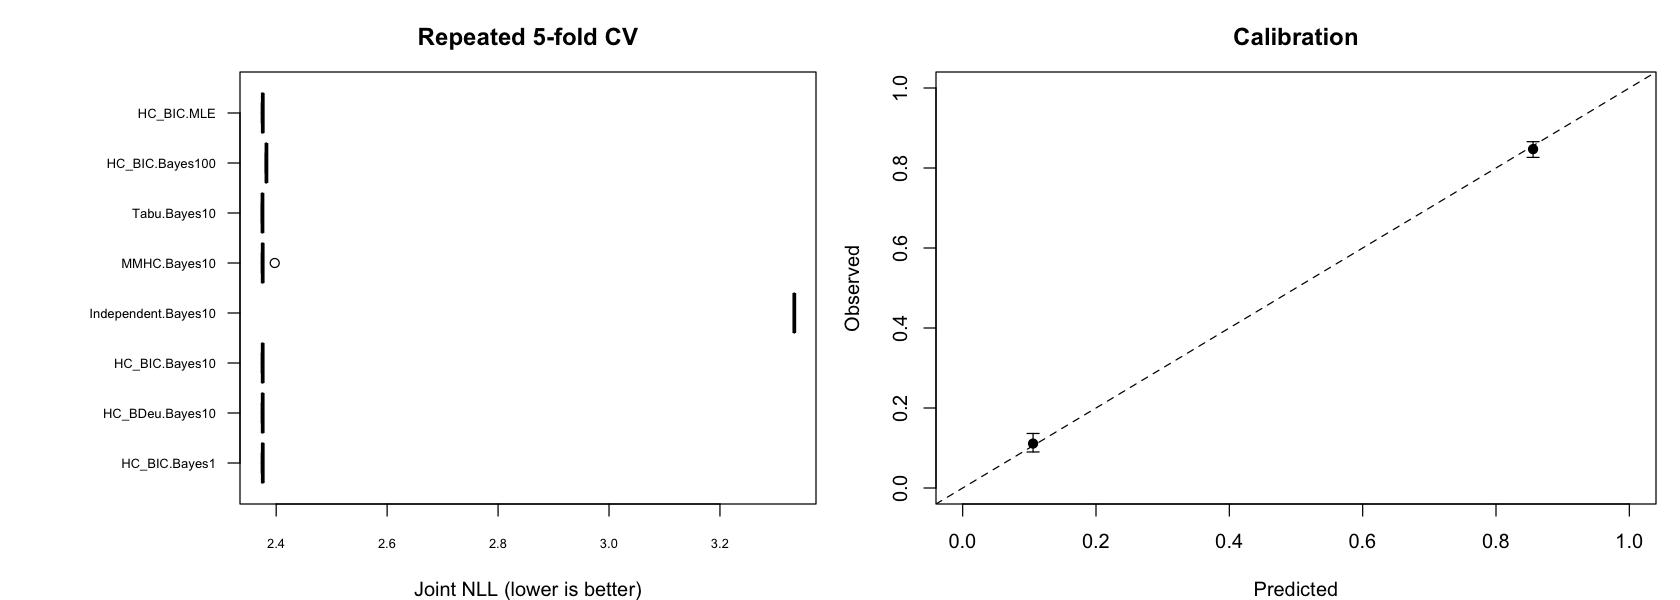

In [9]:
fit<-fit_model(chosen,dev,'Bayes10');p<-pred(fit,evaluation);y<-as.numeric(evaluation[[target]]=='1');baseline<-rep(mean(dev[[target]]=='1'),length(y))
# この5変数を用いた評価は過去使用済み。探索的な再計算として表示。
cal<-do.call(rbind,lapply(0:9,function(b){ix<-p>=b/10 & p<(b+1)/10;N<-sum(ix);if(!N)return(NULL);q<-mean(y[ix]);z<-1.96;mid<-(q+z*z/(2*N))/(1+z*z/N);half<-z*sqrt(q*(1-q)/N+z*z/(4*N*N))/(1+z*z/N);data.frame(bin=paste0(b/10,'-',(b+1)/10),n=N,predicted=mean(p[ix]),observed=q,absolute_gap=abs(q-mean(p[ix])),Wilson_low=mid-half,Wilson_high=mid+half)}))
show('calibration',cal,'gapは小さいほど良好ですが、小標本ビンの見かけの差には注意。±0.05などの許容幅は、意思決定の影響から別途合意が必要です。Wilson区間に予測が入ることだけで校正合格とは判定しません。')
set.seed(900);dif<-binary_loss(y,baseline)-binary_loss(y,p);bs<-replicate(2000,mean(sample(dif,replace=TRUE)));improvement<-data.frame(mean=mean(dif),low=quantile(bs,.025),high=quantile(bs,.975),Brier_BN=mean((y-p)^2),Brier_baseline=mean((y-baseline)^2),Brier_skill=1-mean((y-p)^2)/mean((y-baseline)^2))
show('baseline_comparison',improvement,'対数損失改善>0、Brier skill>0なら基準より良好。Brier skill=0は同じ、1は完全予測、負は悪化。区間は固定モデルと独立行を仮定し、評価標本のばらつきだけを表します。実務採用には最小改善幅が必要です。')
par(bg='white',mfrow=c(1,2),mar=c(4,10,3,1));boxplot(joint_NLL~interaction(algorithm,method,drop=TRUE),data=run_scores,horizontal=TRUE,las=1,cex.axis=.65,ylab='',xlab='Joint NLL (lower is better)',main='Repeated 5-fold CV');par(mar=c(4,4,3,1));plot(cal$predicted,cal$observed,xlim=c(0,1),ylim=c(0,1),xlab='Predicted',ylab='Observed',pch=19,main='Calibration');abline(0,1,lty=2);arrows(cal$predicted,cal$Wilson_low,cal$predicted,cal$Wilson_high,angle=90,code=3,length=.05)

## 10. 判断票：妥当性を単一スコアで決めない

### 実務での最終判断の進め方
1. 数値的整合が崩れていれば利用しない。CPTの和1などは必要条件で十分条件ではない。
2. 構造は訓練スコアだけでなく、繰り返したCVで基準を上回るか確認する。
3. パラメータは親状態ごとの件数・区間幅を確認し、広い箇所の説明を控える。ISSで大きく変わる場合は事前への依存を明記。
4. 辺は複数seed・手法・境界で残るものを安定候補とし、境界付近は保留する。
5. 関連の大きさ、対象範囲、取得時点、誤判定コストから業務上の最小改善を定める。

このNotebookは「計算上・統計上の確認」と「業務で採用して良い」を分けた判断票を出力します。全体の一括合格を自動判定しません。実データでは別期間・別施設での検証が次の段階です。

In [10]:
judgement<-data.frame(check=c('Probability validity','Repeated CV vs independent','CPT precision example','Finite bootstrap precision','Business acceptability'),result=c(if(valid_fit(fit))'passed numerical check'else'failed',paste(sum(stability_cv$positive_run_fraction==1 & stability_cv$algorithm!='Independent'),'configurations improved in every split'),paste(sum(cpt$width>CONFIG$probability_width),'contexts exceed demo width 0.20'),if(max(edges$MC_halfwidth)<=CONFIG$mc_halfwidth)'within configured MC target'else'increase repetitions','not determined: minimum improvement/cost not specified'))
show('validation_decisions',judgement,'統計上の支持・数値的整合・業務上の妥当性は別の判定です。実務採用の自動合格は出しません。')
report<-paste0('# RESULT：R/bnlearnの妥当性検証\n\n',md_table(judgement),'\n\n## 構造比較\n\n',md_table(scores),'\n\n## 反復交差検証\n\n',md_table(cv_summary),'\n\n## パラメータ精度\n\n',md_table(cpt),'\n\n## 関係の安定性\n\n',md_table(edges),'\n\n## 判断上の制約\n\n人工データ・既存評価標本の再利用。構造に正解ラベルを使わない。絶対BIC、出現率0.85、CPT幅0.20などを普遍的合格基準としない。出力の意味と根拠はNotebookのMarkdownセルを参照。')
writeLines(report,'RESULT.md');IRdisplay::display_markdown(report)
saveRDS(list(config=CONFIG,networks=nets,fitted=fit,bootstrap=boots),'results/models_and_settings.rds');capture.output(sessionInfo(),file='results/sessionInfo.txt')
stopifnot(nrow(cv)==CONFIG$cv_runs*CONFIG$cv_folds*nrow(specs),all(cv$valid_CPT),nrow(edges)==20,valid_fit(fit))
cat('All numerical checks passed.\n')
# 今回の数値に基づく読み取りを再実行時に更新する。
hc_edges<-edges[edges$algorithm=='hc',];tabu_edges<-edges[edges$algorithm=='tabu',]
comparison<-merge(hc_edges[,c('from','to','strength')],tabu_edges[,c('from','to','strength')],by=c('from','to'),suffixes=c('_hc','_tabu'))
comparison$algorithm_gap<-abs(comparison$strength_hc-comparison$strength_tabu)
comparison<-comparison[order(-comparison$algorithm_gap),]
show('algorithm_dependence',comparison,'大きな差がある辺はアルゴリズム依存です。反復回数を増やして計算誤差を減らしても、探索法の違いは解消しない場合があります。')
row<-comparison[1,];stable_count<-sum(comparison$strength_hc>.95 & comparison$strength_tabu>.95)
summary_text<-paste0('## 今回の出力をどう読むか\n\n',
'- 両手法で出現率0.95を超える辺は **',stable_count,'本**。この境界は本例の確認値です。\n',
'- 手法差が最も大きい **',row$from,'―',row$to,'** はHC=',round(row$strength_hc*100,1),'%、Tabu=',round(row$strength_tabu*100,1),'%。単一手法だけで安定した関係と断定せず保留します。\n',
'- CPTの95%信用区間幅の最大値は **',round(max(cpt$width)*100,2),'ポイント**。全セルで今回の暫定幅20ポイント以内ですが、構造を固定した推定精度の確認です。\n',
'- 再学習の出現率のMonte Carlo半幅最大は **',round(max(edges$MC_halfwidth)*100,2),'ポイント**。今回の計算精度目標±2ポイントを確認し、都合のよい結論を得るための追加反復はしません。\n',
'- 反復CVの差が小さい候補同士を順位だけで優劣断定しません。実務の必要精度、費用、対象範囲が未定なので採用の総合判定は保留です。')
IRdisplay::display_markdown(summary_text)
cat(paste0('\n\n',summary_text),file='RESULT.md',append=TRUE)


### validation_decisions

| check | result |
| --- | --- |
| Probability validity | passed numerical check |
| Repeated CV vs independent | 7 configurations improved in every split |
| CPT precision example | 0 contexts exceed demo width 0.20 |
| Finite bootstrap precision | within configured MC target |
| Business acceptability | not determined: minimum improvement/cost not specified |

統計上の支持・数値的整合・業務上の妥当性は別の判定です。実務採用の自動合格は出しません。

# RESULT：R/bnlearnの妥当性検証

| check | result |
| --- | --- |
| Probability validity | passed numerical check |
| Repeated CV vs independent | 7 configurations improved in every split |
| CPT precision example | 0 contexts exceed demo width 0.20 |
| Finite bootstrap precision | within configured MC target |
| Business acceptability | not determined: minimum improvement/cost not specified |

## 構造比較

| algorithm | edges | parameters | BIC_bnlearn | BDeu | gap_from_best_BIC | conventional_delta_BIC |
| --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| HC_BDeu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Tabu | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| MMHC | 5.0000 | 11.0000 | -5731.4617 | -5730.7337 | 0.0000 | 0.0000 |
| Independent | 0.0000 | 5.0000 | -8017.8055 | -8013.4292 | 2286.3437 | 4572.6875 |

## 反復交差検証

| algorithm | method | runs | joint_NLL_mean | joint_NLL_min | joint_NLL_max | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HC_BIC | Bayes1 | 10.0000 | 2.3754 | 2.3732 | 2.3767 | 0.3830 | 0.1120 |
| HC_BDeu | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes10 | 10.0000 | 2.3753 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| Independent | Bayes10 | 10.0000 | 3.3339 | 3.3331 | 3.3347 | 0.6792 | 0.2431 |
| MMHC | Bayes10 | 10.0000 | 2.3774 | 2.3733 | 2.3974 | 0.3830 | 0.1120 |
| Tabu | Bayes10 | 10.0000 | 2.3752 | 2.3733 | 2.3767 | 0.3830 | 0.1120 |
| HC_BIC | Bayes100 | 10.0000 | 2.3821 | 2.3804 | 2.3834 | 0.3845 | 0.1123 |
| HC_BIC | MLE | 10.0000 | 2.3754 | 2.3733 | 2.3768 | 0.3830 | 0.1120 |

## パラメータ精度

| variable | parents | n_context | events | MLE | Bayes10 | low | high | width | precision_check |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cloudy | (none) | 2400.0000 | 1215.0000 | 0.5062 | 0.5062 | 0.4863 | 0.5262 | 0.0399 | within_demo_tolerance |
| Rain | Cloudy=0 | 1185.0000 | 209.0000 | 0.1764 | 0.1777 | 0.1565 | 0.1999 | 0.0434 | within_demo_tolerance |
| Rain | Cloudy=1 | 1215.0000 | 973.0000 | 0.8008 | 0.7996 | 0.7767 | 0.8216 | 0.0449 | within_demo_tolerance |
| Sprinkler | Cloudy=0 | 1185.0000 | 612.0000 | 0.5165 | 0.5164 | 0.4880 | 0.5447 | 0.0568 | within_demo_tolerance |
| Sprinkler | Cloudy=1 | 1215.0000 | 112.0000 | 0.0922 | 0.0939 | 0.0781 | 0.1108 | 0.0327 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=0 | 695.0000 | 36.0000 | 0.0518 | 0.0534 | 0.0380 | 0.0713 | 0.0333 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=0 | 981.0000 | 879.0000 | 0.8960 | 0.8950 | 0.8751 | 0.9134 | 0.0383 | within_demo_tolerance |
| WetGrass | Rain=0,Sprinkler=1 | 523.0000 | 418.0000 | 0.7992 | 0.7978 | 0.7625 | 0.8310 | 0.0686 | within_demo_tolerance |
| WetGrass | Rain=1,Sprinkler=1 | 201.0000 | 196.0000 | 0.9751 | 0.9693 | 0.9416 | 0.9883 | 0.0467 | within_demo_tolerance |
| Slippery | WetGrass=0 | 871.0000 | 90.0000 | 0.1033 | 0.1056 | 0.0861 | 0.1268 | 0.0406 | within_demo_tolerance |
| Slippery | WetGrass=1 | 1529.0000 | 1310.0000 | 0.8568 | 0.8556 | 0.8376 | 0.8727 | 0.0352 | within_demo_tolerance |

## 関係の安定性

| algorithm | from | to | strength | seed_range | MC_low | MC_high | direction | MC_halfwidth |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| hc | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Rain | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Cloudy | Slippery | 0.0010 | 0.0020 | 0.0003 | 0.0029 | 0.8333 | 0.0013 |
| tabu | Cloudy | Slippery | 0.0017 | 0.0030 | 0.0007 | 0.0039 | 0.9000 | 0.0016 |
| hc | Rain | Slippery | 0.0030 | 0.0020 | 0.0016 | 0.0057 | 0.5556 | 0.0021 |
| tabu | Rain | Slippery | 0.0050 | 0.0030 | 0.0030 | 0.0082 | 0.9000 | 0.0026 |
| hc | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4995 | 0.0006 |
| tabu | Cloudy | Sprinkler | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.4997 | 0.0006 |
| hc | Rain | Sprinkler | 0.6457 | 0.0160 | 0.6284 | 0.6626 | 0.4987 | 0.0171 |
| tabu | Rain | Sprinkler | 0.1270 | 0.0060 | 0.1156 | 0.1394 | 0.5000 | 0.0119 |
| hc | Slippery | Sprinkler | 0.0047 | 0.0040 | 0.0028 | 0.0078 | 0.3929 | 0.0025 |
| tabu | Slippery | Sprinkler | 0.0067 | 0.0040 | 0.0043 | 0.0103 | 0.1250 | 0.0030 |
| hc | Cloudy | WetGrass | 0.2727 | 0.0270 | 0.2570 | 0.2889 | 0.5000 | 0.0159 |
| tabu | Cloudy | WetGrass | 0.0003 | 0.0010 | 0.0001 | 0.0019 | 0.5000 | 0.0009 |
| hc | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6763 | 0.0006 |
| tabu | Rain | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |
| hc | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.3228 | 0.0006 |
| tabu | Slippery | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.0635 | 0.0006 |
| hc | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.6770 | 0.0006 |
| tabu | Sprinkler | WetGrass | 1.0000 | 0.0000 | 0.9987 | 1.0000 | 0.9363 | 0.0006 |

## 判断上の制約

人工データ・既存評価標本の再利用。構造に正解ラベルを使わない。絶対BIC、出現率0.85、CPT幅0.20などを普遍的合格基準としない。出力の意味と根拠はNotebookのMarkdownセルを参照。

All numerical checks passed.


### algorithm_dependence

| from | to | strength_hc | strength_tabu | algorithm_gap |
| --- | --- | --- | --- | --- |
| Rain | Sprinkler | 0.6457 | 0.1270 | 0.5187 |
| Cloudy | WetGrass | 0.2727 | 0.0003 | 0.2723 |
| Rain | Slippery | 0.0030 | 0.0050 | 0.0020 |
| Slippery | Sprinkler | 0.0047 | 0.0067 | 0.0020 |
| Cloudy | Slippery | 0.0010 | 0.0017 | 0.0007 |
| Cloudy | Rain | 1.0000 | 1.0000 | 0.0000 |
| Cloudy | Sprinkler | 1.0000 | 1.0000 | 0.0000 |
| Rain | WetGrass | 1.0000 | 1.0000 | 0.0000 |
| Slippery | WetGrass | 1.0000 | 1.0000 | 0.0000 |
| Sprinkler | WetGrass | 1.0000 | 1.0000 | 0.0000 |

大きな差がある辺はアルゴリズム依存です。反復回数を増やして計算誤差を減らしても、探索法の違いは解消しない場合があります。

## 今回の出力をどう読むか

- 両手法で出現率0.95を超える辺は **5本**。この境界は本例の確認値です。
- 手法差が最も大きい **Rain―Sprinkler** はHC=64.6%、Tabu=12.7%。単一手法だけで安定した関係と断定せず保留します。
- CPTの95%信用区間幅の最大値は **6.86ポイント**。全セルで今回の暫定幅20ポイント以内ですが、構造を固定した推定精度の確認です。
- 再学習の出現率のMonte Carlo半幅最大は **1.71ポイント**。今回の計算精度目標±2ポイントを確認し、都合のよい結論を得るための追加反復はしません。
- 反復CVの差が小さい候補同士を順位だけで優劣断定しません。実務の必要精度、費用、対象範囲が未定なので採用の総合判定は保留です。

## 11. モデルを選ぶ手続き自体の検証：ネストしたCV

### 提示する意味
通常のCVで複数候補を比較して最良値を選ぶと、選択に使った評価値自体が楽観的になり得ます。ここでは外側5foldを評価専用に残し、内側3foldだけで探索法・ISSを選びます。候補はHC/Tabu×ISS1/10/100と独立モデルの計7つ。主選択指標は全変数joint NLLで固定します。

小さいNLLと基準より正の改善は選択手続きの内部妥当性を支えますが、5foldは独立な実験ではありません。結果の点数で真の構造を証明せず、別施設の有効性も主張しません。候補選択ログを残し、最も良いfoldだけを提示しません。反復ネストCVを追加する場合は分割変更への安定性を調べるために行い、独立標本が増えたとは扱いません。

In [11]:
# 目的は全項目の説明。内側の主選択指標はjoint NLLで固定する。
make_folds<-function(d,k,seed){set.seed(seed);f<-integer(nrow(d));for(z in levels(d[[target]])){ix<-which(d[[target]]==z);f[ix]<-sample(rep(seq_len(k),length.out=length(ix)))};f}
selection_specs<-expand.grid(algorithm=c('HC_BIC','Tabu'),method=c('Bayes1','Bayes10','Bayes100'),stringsAsFactors=FALSE)
selection_specs<-rbind(selection_specs,data.frame(algorithm='Independent',method='Bayes10'))
outer<-make_folds(dev,5,871);nested_rows<-list();selection_rows<-list()
for(o in 1:5){
 train_o<-dev[outer!=o,];test_o<-dev[outer==o,];inner<-make_folds(train_o,3,900+o);inner_rows<-list()
 for(fold in 1:3){tr<-train_o[inner!=fold,];te<-train_o[inner==fold,];gs<-setNames(lapply(c('HC_BIC','Tabu','Independent'),function(a)learn(tr,a)),c('HC_BIC','Tabu','Independent'))
  for(i in seq_len(nrow(selection_specs))){sp<-selection_specs[i,];fm<-fit_model(gs[[sp$algorithm]],tr,sp$method);inner_rows[[length(inner_rows)+1]]<-data.frame(candidate=i,n=nrow(te),NLL=assess(fm,te)['joint_NLL'])}}
 inner_rows<-do.call(rbind,inner_rows);cv_inner<-vapply(seq_len(nrow(selection_specs)),function(i){z<-inner_rows[inner_rows$candidate==i,];weighted.mean(z$NLL,z$n)},numeric(1));winner<-which.min(cv_inner);sp<-selection_specs[winner,]
 for(i in seq_len(nrow(selection_specs)))selection_rows[[length(selection_rows)+1]]<-data.frame(outer=o,selection_specs[i,],inner_NLL=cv_inner[i],selected=i==winner)
 g<-learn(train_o,sp$algorithm);fm<-fit_model(g,train_o,sp$method)
 nested_rows[[o]]<-data.frame(outer=o,algorithm=sp$algorithm,method=sp$method,n=nrow(test_o),t(assess(fm,test_o)),baseline_joint_NLL=assess(fit_model(learn(train_o,'Independent'),train_o,'Bayes10'),test_o)['joint_NLL'])
}
nested<-do.call(rbind,nested_rows);nested$improvement<-nested$baseline_joint_NLL-nested$joint_NLL
write.csv(do.call(rbind,selection_rows),'results/nested_selection_log.csv',row.names=FALSE)
show('nested_CV',nested,'外側の5foldは候補選択に使っていません。評価しているのは7候補から選ぶ手続きで、最終的に学習した特定のネットワークそのものではありません。同じ母集団内の内部検証です。')

### nested_CV

| outer | algorithm | method | n | joint_NLL | target_NLL | Brier | baseline_joint_NLL | improvement |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1.0000 | HC_BIC | Bayes1 | 480.0000 | 2.2971 | 0.3503 | 0.0989 | 3.3418 | 1.0447 |
| 2.0000 | HC_BIC | Bayes10 | 480.0000 | 2.4086 | 0.3768 | 0.1101 | 3.3700 | 0.9615 |
| 3.0000 | HC_BIC | Bayes1 | 480.0000 | 2.4150 | 0.3920 | 0.1154 | 3.3077 | 0.8928 |
| 4.0000 | Tabu | Bayes10 | 480.0000 | 2.4251 | 0.4094 | 0.1226 | 3.3184 | 0.8933 |
| 5.0000 | HC_BIC | Bayes1 | 480.0000 | 2.3440 | 0.3877 | 0.1131 | 3.3433 | 0.9993 |

外側の5foldは候補選択に使っていません。評価しているのは7候補から選ぶ手続きで、最終的に学習した特定のネットワークそのものではありません。同じ母集団内の内部検証です。

## 12. 直接の関係の証拠と、構造が主張する独立性の点検

### 関係の存在と「関係しない」という説明を両方点検する
学習構造が示すエッジについて、子の他の親を条件にした関連を調べます。またDAGがd-separationとして主張する全ての二変数の条件付き独立性を列挙し、開発標本とは別の既存評価標本で照合します。

`CMI_bits`は条件付き相互情報量で、0から離れるほど条件付きの関連が大きい。`given`は条件として揃えた項目です。`min_expected`は独立性の下での条件内期待度数の最小値で、小さいほど漸近近似に注意が必要なため、ここではbnlearnのMonte Carlo検定`mc-mi`（4,999回）を使います。小さいpの細かな順位は比較しません。

**同じp値でも、問う仮説によって読み方が逆になります。** edge行で小さいpは関連の証拠。implied_independence行で小さいpは構造の説明と観測が合わない証拠。大きいpは独立性や妥当性を証明しません。全行をまとめてHolm補正し、検定族の中の誤棄却を抑えます。過去使用済み評価標本で、標本再利用・選択の限界も残ります。

参考：[bnlearn検定一覧](https://www.bnlearn.com/documentation/man/conditional.independence.tests.html)、[ci.test](https://www.bnlearn.com/documentation/man/ci.test.html)。

有限回数でp=0と報告しないよう、bnlearnのMonte Carlo原値（超過回数/B）から回数を復元し、報告用は(超過回数+1)/(B+1)に補正してからHolm補正します。4,999回なので未補正の解像度は1/5,000。参考：[Phipson & Smyth：Permutation p-values should never be zero](https://arxiv.org/abs/1603.05766)。

In [12]:
# 検定族を事前に固定する代わりに、ここでは開発標本だけから決定。既存評価標本で探索的に照合。
conditional_info<-function(d,x,y,z=character()){
 groups<-if(length(z))interaction(d[,z,drop=FALSE],drop=TRUE)else factor(rep('all',nrow(d)))
 mi<-0;minimum<-Inf
 for(ix in split(seq_len(nrow(d)),groups)){
  tab<-table(d[[x]][ix],d[[y]][ix]);n<-sum(tab);pp<-tab/n;expected<-outer(rowSums(tab),colSums(tab))/n
  nz<-tab>0;mi<-mi+n/nrow(d)*sum(pp[nz]*log2(tab[nz]/expected[nz]));positive<-expected[expected>0];if(length(positive))minimum<-min(minimum,positive)
 }
 c(CMI_bits=mi,min_expected=minimum)
}
statements<-list();a<-arcs(chosen)
for(i in seq_len(nrow(a)))statements[[length(statements)+1]]<-list(kind='edge',x=a[i,1],y=a[i,2],z=setdiff(parents(chosen,a[i,2]),a[i,1]))
# 全ての二変数・残り変数の部分集合から、DAGがd-separationを主張するものを列挙。
for(pair in combn(names(dev),2,simplify=FALSE)){
 remain<-setdiff(names(dev),pair);sets<-list(character());for(k in seq_along(remain))sets<-c(sets,combn(remain,k,simplify=FALSE))
 for(z in sets)if(dsep(chosen,pair[1],pair[2],z))statements[[length(statements)+1]]<-list(kind='implied_independence',x=pair[1],y=pair[2],z=z)
}
set.seed(1300);Bperm<-4999
ci_rows<-lapply(statements,function(s){st<-conditional_info(evaluation,s$x,s$y,s$z);tt<-if(length(s$z))ci.test(s$x,s$y,z=s$z,data=evaluation,test='mc-mi',B=Bperm)else ci.test(s$x,s$y,data=evaluation,test='mc-mi',B=Bperm);data.frame(kind=s$kind,x=s$x,y=s$y,given=if(length(s$z))paste(s$z,collapse=',')else '(none)',CMI_bits=st['CMI_bits'],min_expected=st['min_expected'],permutation_p_raw=tt$p.value,permutation_p=(round(tt$p.value*Bperm)+1)/(Bperm+1))})
conditional_tests<-do.call(rbind,ci_rows);conditional_tests$p_Holm<-p.adjust(conditional_tests$permutation_p,method='holm');conditional_tests$reject_independence<-conditional_tests$p_Holm<.05
show('conditional_tests',conditional_tests,'全行を一つの検定族としてHolm補正。edge行で小さいpは条件付き関連の証拠。implied_independence行で小さいpは構造の説明と食い違う証拠です。大きいpは独立性の証明ではありません。rawはbnlearnの原値。報告用は(超過回数+1)/(B+1)に補正し、最小値は0.0002です。小さい値の細かな順位は主張しません。')

### conditional_tests

| kind | x | y | given | CMI_bits | min_expected | permutation_p_raw | permutation_p | p_Holm | reject_independence |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| edge | WetGrass | Slippery | (none) | 0.4023 | 294.7095 | 0.0000 | 0.0002 | 0.0042 | TRUE |
| edge | Cloudy | Rain | (none) | 0.2959 | 484.5540 | 0.0000 | 0.0002 | 0.0042 | TRUE |
| edge | Rain | WetGrass | Sprinkler | 0.4481 | 21.6749 | 0.0000 | 0.0002 | 0.0042 | TRUE |
| edge | Sprinkler | WetGrass | Rain | 0.2888 | 15.9522 | 0.0000 | 0.0002 | 0.0042 | TRUE |
| edge | Cloudy | Sprinkler | (none) | 0.1520 | 296.2785 | 0.0000 | 0.0002 | 0.0042 | TRUE |
| implied_independence | Cloudy | WetGrass | Rain,Sprinkler | 0.0005 | 0.4375 | 0.9950 | 0.995 |    1 | FALSE |
| implied_independence | Cloudy | WetGrass | Rain,Sprinkler,Slippery | 0.0013 | 0.3583 | 0.9598 | 0.96 |    1 | FALSE |
| implied_independence | Cloudy | Slippery | WetGrass | 0.0001 | 26.3333 | 0.9288 | 0.929 |    1 | FALSE |
| implied_independence | Cloudy | Slippery | Rain,Sprinkler | 0.0002 | 4.6559 | 0.9702 | 0.97 |    1 | FALSE |
| implied_independence | Cloudy | Slippery | Rain,WetGrass | 0.0006 | 1.1868 | 0.8130 | 0.813 |    1 | FALSE |
| implied_independence | Cloudy | Slippery | Sprinkler,WetGrass | 0.0009 | 0.4000 | 0.6441 | 0.644 |    1 | FALSE |
| implied_independence | Cloudy | Slippery | Rain,Sprinkler,WetGrass | 0.0010 | 0.4054 | 0.9610 | 0.961 |    1 | FALSE |
| implied_independence | Rain | Sprinkler | Cloudy | 0.0002 | 16.8222 | 0.7209 | 0.721 |    1 | FALSE |
| implied_independence | Rain | Slippery | WetGrass | 0.0005 | 10.1111 | 0.5015 | 0.502 |    1 | FALSE |
| implied_independence | Rain | Slippery | Cloudy,WetGrass | 0.0010 | 1.3671 | 0.6395 | 0.64 |    1 | FALSE |
| implied_independence | Rain | Slippery | Sprinkler,WetGrass | 0.0016 | 0.1333 | 0.3547 | 0.355 |    1 | FALSE |
| implied_independence | Rain | Slippery | Cloudy,Sprinkler,WetGrass | 0.0017 | 0.1389 | 0.7690 | 0.769 |    1 | FALSE |
| implied_independence | Sprinkler | Slippery | WetGrass | 0.0001 | 8.3333 | 0.8242 | 0.824 |    1 | FALSE |
| implied_independence | Sprinkler | Slippery | Cloudy,WetGrass | 0.0010 | 0.3165 | 0.5823 | 0.582 |    1 | FALSE |
| implied_independence | Sprinkler | Slippery | Rain,WetGrass | 0.0013 | 0.0989 | 0.4343 | 0.434 |    1 | FALSE |
| implied_independence | Sprinkler | Slippery | Cloudy,Rain,WetGrass | 0.0017 | 0.0833 | 0.6819 | 0.682 |    1 | FALSE |

全行を一つの検定族としてHolm補正。edge行で小さいpは条件付き関連の証拠。implied_independence行で小さいpは構造の説明と食い違う証拠です。大きいpは独立性の証明ではありません。rawはbnlearnの原値。報告用は(超過回数+1)/(B+1)に補正し、最小値は0.0002です。小さい値の細かな順位は主張しません。

## 13. パラメータの全体適合：32状態の頻度を再現できるか

### CPTの和が1でも、実際の頻度に合うとは限らない
学習済みBNが予測する32状態の期待度数と、評価標本の観測度数を比較します。最大の食い違いを上位10件表示し、全体のPearson型ずれ量を、その学習済み分布から生成した2,000標本の分布と比較します。

`statistic`は大きいほど不一致、simulation_pは小さいほどこの固定分布からは説明しづらい結果です。各状態の検定を32個行う代わりに全体の一つの診断を主とし、上位残差は理由を探すための探索表にします。残差の絶対値2を自動合格／不合格にしません。学習済み分布を固定した条件付き診断で、パラメータ推定のばらつきは別の検証で扱います。pが大きくても低い検出力の可能性があるので「モデルが正しい」とは言いません。

In [13]:
jp<-joint(fitted);key<-function(d)apply(d[,names(dev),drop=FALSE],1,paste,collapse='|')
counts<-tabulate(match(key(evaluation),key(jp)),nbins=nrow(jp));expected<-nrow(evaluation)*jp$prob
Tobs<-sum((counts-expected)^2/expected)
set.seed(1400);simulated<-rmultinom(2000,nrow(evaluation),jp$prob);Tsim<-colSums((simulated-expected)^2/expected)
p_global<-(1+sum(Tsim>=Tobs))/(ncol(simulated)+1)
patterns<-cbind(jp[,names(dev)],observed=counts,expected=expected,standardized_residual=(counts-expected)/sqrt(expected));patterns<-patterns[order(-abs(patterns$standardized_residual)),]
show('pattern_discrepancy',head(patterns,10),'観測数−予測数を予測数の平方根で割った残差。正は過少予測、負は過大予測。絶対値が大きい状態を点検します。32状態を探した後の上位表なので、±2だけで個別の有意性を判定しません。')
show('global_fit_simulation',data.frame(statistic=Tobs,simulation_p=p_global,replicates=ncol(simulated),minimum_expected=min(expected)),'固定した学習済み分布から評価標本と同じ2,000行を2,000回模擬生成。小さいpはこの分布と観測頻度の不一致を示します。大きいpはモデルの正しさを保証しません。学習パラメータの不確実性は含めません。')

### pattern_discrepancy

| Cloudy | Rain | Sprinkler | WetGrass | Slippery | observed | expected | standardized_residual |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 1 | 0 | 1 | 1 | 84.0000 | 65.0021 | 2.3564 |
| 0 | 0 | 0 | 1 | 1 | 10.0000 | 17.9444 | -1.8754 |
| 0 | 0 | 1 | 0 | 0 | 61.0000 | 75.8298 | -1.7030 |
| 0 | 0 | 1 | 1 | 0 | 60.0000 | 48.3056 | 1.6826 |
| 1 | 1 | 1 | 0 | 0 | 0.0000 | 2.0871 | -1.4447 |
| 1 | 0 | 0 | 0 | 0 | 138.0000 | 155.6646 | -1.4158 |
| 0 | 1 | 1 | 1 | 1 | 87.0000 | 75.1666 | 1.3649 |
| 1 | 0 | 0 | 1 | 0 | 0.0000 | 1.4178 | -1.1907 |
| 1 | 0 | 0 | 1 | 1 | 5.0000 | 8.4013 | -1.1735 |
| 0 | 1 | 1 | 0 | 0 | 1.0000 | 2.4897 | -0.9441 |

観測数−予測数を予測数の平方根で割った残差。正は過少予測、負は過大予測。絶対値が大きい状態を点検します。32状態を探した後の上位表なので、±2だけで個別の有意性を判定しません。

### global_fit_simulation

| statistic | simulation_p | replicates | minimum_expected |
| --- | --- | --- | --- |
| 31.0840 | 0.462 | 2000.0000 | 0.2464 |

固定した学習済み分布から評価標本と同じ2,000行を2,000回模擬生成。小さいpはこの分布と観測頻度の不一致を示します。大きいpはモデルの正しさを保証しません。学習パラメータの不確実性は含めません。

## 14. データの量・推定方法を変えた頑健性

### データを増やす必要があるか、確率差をどの精度で説明できるか
150/300/600/1,200/2,400行で再学習し、損失とばらつきの推移を見ます。標本数が少ないときだけ悪化すればデータ不足の示唆、十分な標本でも悪ければ構造・特徴・測定等の見直し候補です。追加データの効果を保証する曲線ではありません。

続いて200回、構造から再学習したWetGrass=0/1の条件付き確率を比較します。固定構造のCPT信用区間と、構造再選択を含めた探索的な範囲の両方を示します。200回の2.5百分位は端の約5標本で決まるため粗い推定です。重要な閾値付近では1,000〜数千回に増やし、複数seedで端の値が動かないか確認してください。回数を増やしても欠測・選択・測定の偏りは改善しません。

In [14]:
set.seed(1500);learning_rows<-list()
for(size in c(150,300,600,1200,nrow(dev)))for(rep in 1:5){ix<-sample.int(nrow(dev),size);dd<-dev[ix,];ff<-fit_model(learn(dd,'HC_BIC'),dd,'Bayes10');learning_rows[[length(learning_rows)+1]]<-data.frame(n_train=size,replicate=rep,t(assess(ff,evaluation)))}
learning_curve<-do.call(rbind,learning_rows);show('learning_curve',learning_curve,'少ないデータで損失や変動が大きいかを点検します。開発標本全件の場合は同じデータなので、順序だけ変えても独立反復ではありません。評価標本は共通・使用済みのため標本数を選ぶ確証的試験ではありません。')
set.seed(1600);scenario_samples<-replicate(200,{dd<-dev[sample.int(nrow(dev),replace=TRUE),];ff<-fit_model(learn(dd,'HC_BIC'),dd,'Bayes10');jj<-joint(ff);c(dry=query(jj,list(WetGrass='0')),wet=query(jj,list(WetGrass='1')))})
scenario_intervals<-data.frame(condition=c('WetGrass=0','WetGrass=1'),estimate=c(query(joint(fitted),list(WetGrass='0')),query(joint(fitted),list(WetGrass='1'))),low=apply(scenario_samples,1,quantile,.025),high=apply(scenario_samples,1,quantile,.975))
show('refitted_scenario_intervals',scenario_intervals,'構造と確率を毎回学習し直した200回のパーセンタイル範囲。固定構造のCPT信用区間とは対象が異なり、構造選択を含むため探索的な安定性範囲として示します。端の分位点は粗く、重要判断では1,000回以上等で安定を確認します。')

### learning_curve

| n_train | replicate | joint_NLL | target_NLL | Brier |
| --- | --- | --- | --- | --- |
| 150.0000 | 1.0000 | 2.4376 | 0.4061 | 0.1202 |
| 150.0000 | 2.0000 | 2.4245 | 0.4169 | 0.1238 |
| 150.0000 | 3.0000 | 2.4182 | 0.4078 | 0.1211 |
| 150.0000 | 4.0000 | 2.4206 | 0.4085 | 0.1210 |
| 150.0000 | 5.0000 | 2.4078 | 0.4000 | 0.1186 |
| 300.0000 | 1.0000 | 2.3947 | 0.4030 | 0.1194 |
| 300.0000 | 2.0000 | 2.3971 | 0.4024 | 0.1193 |
| 300.0000 | 3.0000 | 2.3851 | 0.4019 | 0.1191 |
| 300.0000 | 4.0000 | 2.3975 | 0.4009 | 0.1188 |
| 300.0000 | 5.0000 | 2.3836 | 0.4022 | 0.1193 |
| 600.0000 | 1.0000 | 2.3807 | 0.4001 | 0.1187 |
| 600.0000 | 2.0000 | 2.3839 | 0.4006 | 0.1188 |
| 600.0000 | 3.0000 | 2.3880 | 0.4008 | 0.1189 |
| 600.0000 | 4.0000 | 2.3985 | 0.4022 | 0.1192 |
| 600.0000 | 5.0000 | 2.3880 | 0.4010 | 0.1189 |
| 1200.0000 | 1.0000 | 2.3812 | 0.4006 | 0.1188 |
| 1200.0000 | 2.0000 | 2.3793 | 0.4000 | 0.1186 |
| 1200.0000 | 3.0000 | 2.3800 | 0.4005 | 0.1187 |
| 1200.0000 | 4.0000 | 2.3852 | 0.4010 | 0.1188 |
| 1200.0000 | 5.0000 | 2.3805 | 0.4000 | 0.1187 |
| 2400.0000 | 1.0000 | 2.3789 | 0.3998 | 0.1186 |
| 2400.0000 | 2.0000 | 2.3789 | 0.3998 | 0.1186 |
| 2400.0000 | 3.0000 | 2.3789 | 0.3998 | 0.1186 |
| 2400.0000 | 4.0000 | 2.3789 | 0.3998 | 0.1186 |
| 2400.0000 | 5.0000 | 2.3789 | 0.3998 | 0.1186 |

少ないデータで損失や変動が大きいかを点検します。開発標本全件の場合は同じデータなので、順序だけ変えても独立反復ではありません。評価標本は共通・使用済みのため標本数を選ぶ確証的試験ではありません。

### refitted_scenario_intervals

| condition | estimate | low | high |
| --- | --- | --- | --- |
| WetGrass=0 | 0.1056 | 0.0881 | 0.1256 |
| WetGrass=1 | 0.8556 | 0.8418 | 0.8746 |

構造と確率を毎回学習し直した200回のパーセンタイル範囲。固定構造のCPT信用区間とは対象が異なり、構造選択を含むため探索的な安定性範囲として示します。端の分位点は粗く、重要判断では1,000回以上等で安定を確認します。

## 15. 条件別の性能とデータ分布の違い

### 全体の平均だけで説明しない
例として天候・降雨条件で区分し、件数、発生数、予測確率、NLL、Brierを示します。条件別で生じる誤差を点検しますが、小さな群での順位を断定しません。顧客層や地域のデータはないため、公平性の検証や部署間の一般化にはなりません。

開発と評価の状態割合の差（百分率ポイント）も確認し、5項目の検定にHolm補正を適用します。p値だけでなく差の大きさを見る必要があります。実際の監視では基準期間・許容差・連続何回で対応するかを先に決め、毎日検定を繰り返す際の誤警報を考慮します。今回は時系列ではなく教材上の二標本比較です。

In [15]:
p_eval<-pred(fitted,evaluation);y_eval<-as.numeric(evaluation[[target]]=='1');group_rows<-list()
for(v in c('Cloudy','Rain'))for(state in c('0','1')){ix<-evaluation[[v]]==state;group_rows[[length(group_rows)+1]]<-data.frame(group=paste(v,state,sep='='),n=sum(ix),events=sum(y_eval[ix]),mean_predicted=mean(p_eval[ix]),observed=mean(y_eval[ix]),target_NLL=mean(binary_loss(y_eval[ix],p_eval[ix])),Brier=mean((y_eval[ix]-p_eval[ix])^2))}
show('subgroups',do.call(rbind,group_rows),'例示的な条件別診断です。期間・施設・顧客層の検証や公平性監査ではありません。群の発生率が違うため損失だけで扱いの不公平を判断しません。')
drift<-do.call(rbind,lapply(names(dev),function(v){p1<-mean(dev[[v]]=='1');p2<-mean(evaluation[[v]]=='1');t<-prop.test(c(sum(dev[[v]]=='1'),sum(evaluation[[v]]=='1')),c(nrow(dev),nrow(evaluation)));data.frame(variable=v,development=p1,evaluation=p2,difference_pp=100*(p2-p1),p=t$p.value)}));drift$p_Holm<-p.adjust(drift$p,'holm')
show('marginal_distribution_shift',drift,'各状態の割合差を点検する例。多重補正後pが大きくても同分布とは証明できず、周辺分布が似ていても項目間の関係は変化し得ます。時間情報がないためドリフト監視の実証ではありません。')

### subgroups

| group | n | events | mean_predicted | observed | target_NLL | Brier |
| --- | --- | --- | --- | --- | --- | --- |
| Cloudy=0 | 1027.0000 | 521.0000 | 0.5094 | 0.5073 | 0.3968 | 0.1174 |
| Cloudy=1 | 973.0000 | 650.0000 | 0.6729 | 0.6680 | 0.4030 | 0.1199 |
| Rain=0 | 996.0000 | 382.0000 | 0.3887 | 0.3835 | 0.3928 | 0.1160 |
| Rain=1 | 1004.0000 | 789.0000 | 0.7876 | 0.7859 | 0.4068 | 0.1213 |

例示的な条件別診断です。期間・施設・顧客層の検証や公平性監査ではありません。群の発生率が違うため損失だけで扱いの不公平を判断しません。

### marginal_distribution_shift

| variable | development | evaluation | difference_pp | p | p_Holm |
| --- | --- | --- | --- | --- | --- |
| Cloudy | 0.5062 | 0.4865 | -1.9750 | 0.203 |    1 |
| Rain | 0.4925 | 0.5020 | 0.9500 | 0.55 |    1 |
| Sprinkler | 0.3017 | 0.3045 | 0.2833 | 0.864 |    1 |
| WetGrass | 0.6371 | 0.6445 | 0.7417 | 0.632 |    1 |
| Slippery | 0.5833 | 0.5855 | 0.2167 | 0.909 |    1 |

各状態の割合差を点検する例。多重補正後pが大きくても同分布とは証明できず、周辺分布が似ていても項目間の関係は変化し得ます。時間情報がないためドリフト監視の実証ではありません。

## 16. ビジネス提示用の根拠台帳と図

### 図の役割を明確にする
**関係図**では矢印を省き、両手法で出現率0.95を超える辺を実線、手法差0.20超の辺を破線で示します。この線種はこの資料の例示ルールで、公式の妥当性閾値ではありません。線の太さで効果量と出現率を同時に表すと混乱するため、本図の太さは「安定候補」の区別にだけ使います。

**確率図**ではCPTの推定値と固定構造95%信用区間を同じ0〜1軸に並べます。業務向けには%で読み替え、親条件と件数を表で添えます。基準値を切り取った軸で差を大きく見せません。

根拠台帳では、辺ごとにHC・Tabu出現率、手法差、相互情報量、関連の大きさを並べます。安定性と効果量は違うため、単一の総合点に合成しません。統計的支持が強くても、測定費用・取得時点・用途が合わなければ業務利用できません。

### business_edge_evidence

| from | to | strength_hc | strength_tabu | algorithm_gap | MI_bits | Cramers_V | presentation_label |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Cloudy | Rain | 1.0000 | 1.0000 | 0.0000 | 0.3034 | 0.6245 | stable_candidate |
| Cloudy | Slippery | 0.0010 | 0.0017 | 0.0007 | 0.0196 | 0.1644 | insufficient_stability |
| Cloudy | Sprinkler | 1.0000 | 1.0000 | 0.0000 | 0.1653 | 0.4622 | stable_candidate |
| Cloudy | WetGrass | 0.2727 | 0.0003 | 0.2723 | 0.0387 | 0.2304 | method_sensitive |
| Rain | Slippery | 0.0030 | 0.0050 | 0.0020 | 0.1213 | 0.4032 | insufficient_stability |
| Rain | Sprinkler | 0.6457 | 0.1270 | 0.5187 | 0.0592 | 0.2825 | method_sensitive |
| Rain | WetGrass | 1.0000 | 1.0000 | 0.0000 | 0.2457 | 0.5581 | stable_candidate |
| Slippery | Sprinkler | 0.0047 | 0.0067 | 0.0020 | 0.0299 | 0.2001 | insufficient_stability |
| Slippery | WetGrass | 1.0000 | 1.0000 | 0.0000 | 0.4283 | 0.7348 | stable_candidate |
| Sprinkler | WetGrass | 1.0000 | 1.0000 | 0.0000 | 0.0656 | 0.2884 | stable_candidate |

stable_candidate:両手法で0.95超という厳しい例示基準。method_sensitive:差0.20超という例示基準。正式な採否や真偽ラベルではありません。p値は別表で全件提示し、都合のよい項目だけを抜き出しません。

pdf 
  2

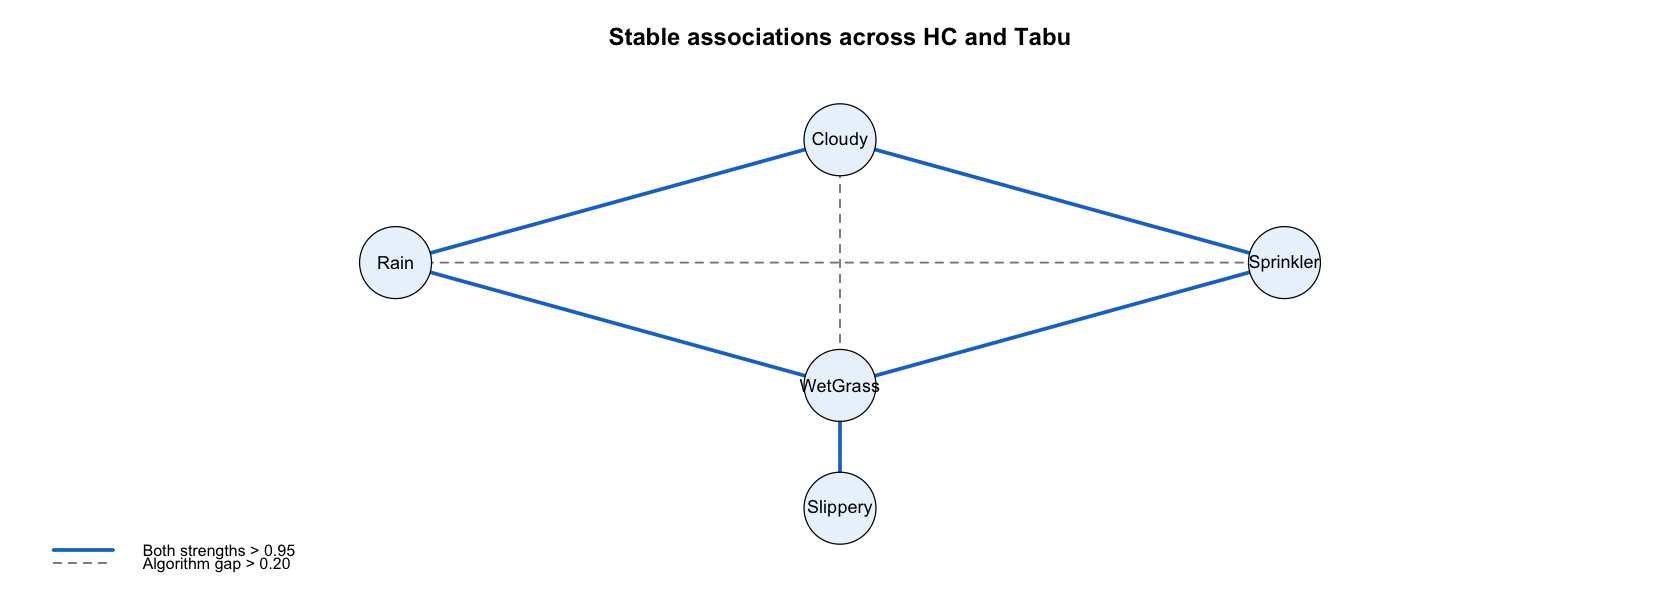

pdf 
  2

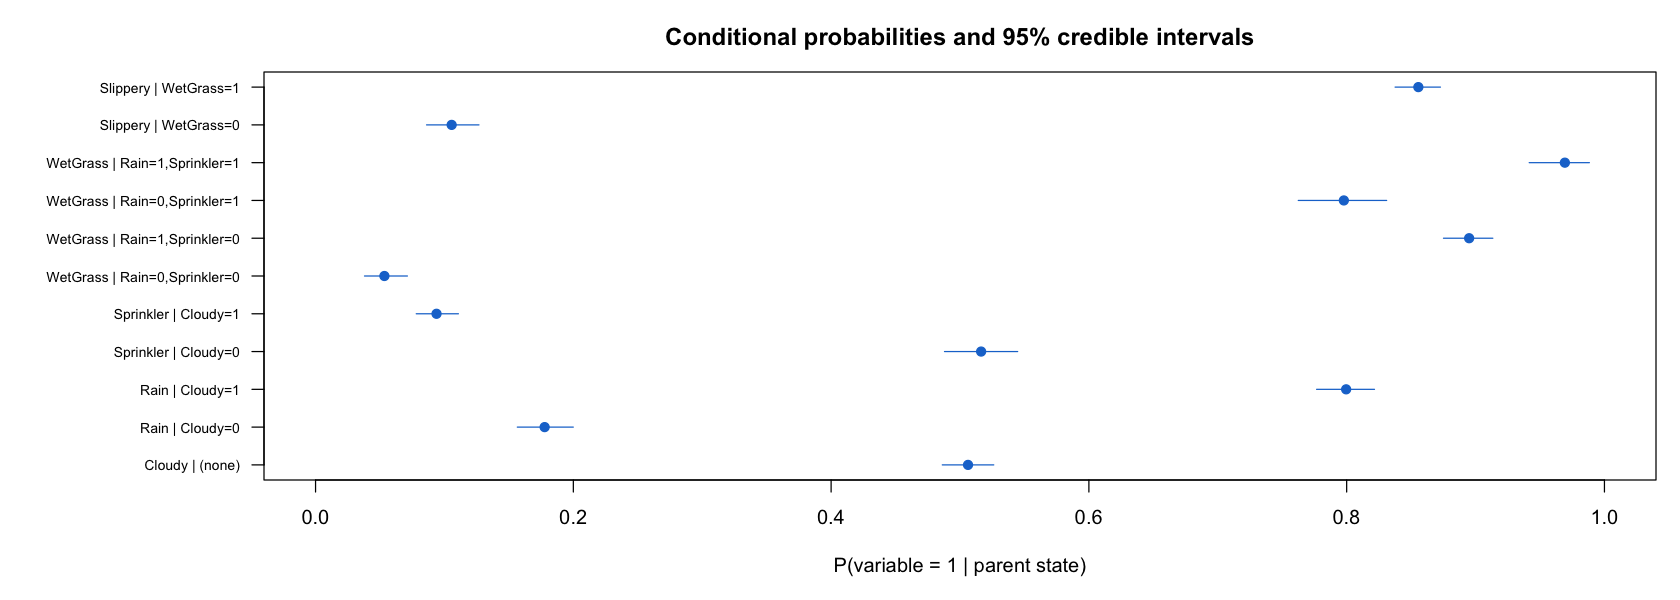

In [16]:
edge_bridge<-merge(comparison,association,by.x=c('from','to'),by.y=c('x','y'),all.x=TRUE)
# 不一致の並びも含め全10組に対応する
for(i in seq_len(nrow(edge_bridge)))if(is.na(edge_bridge$MI_bits[i])){z<-association[association$x==edge_bridge$to[i]&association$y==edge_bridge$from[i],];if(nrow(z)){edge_bridge$MI_bits[i]<-z$MI_bits;edge_bridge$Cramers_V[i]<-z$Cramers_V;edge_bridge$p_Holm[i]<-z$p_Holm}}
edge_bridge$presentation_label<-ifelse(pmin(edge_bridge$strength_hc,edge_bridge$strength_tabu)>.95,'stable_candidate',ifelse(edge_bridge$algorithm_gap>.20,'method_sensitive','insufficient_stability'))
show('business_edge_evidence',edge_bridge[,c('from','to','strength_hc','strength_tabu','algorithm_gap','MI_bits','Cramers_V','presentation_label')],'stable_candidate:両手法で0.95超という厳しい例示基準。method_sensitive:差0.20超という例示基準。正式な採否や真偽ラベルではありません。p値は別表で全件提示し、都合のよい項目だけを抜き出しません。')
# 矢印を省いた関係図。向きより存在の安定性を伝える。
plot_network<-function(){
 pos<-rbind(Cloudy=c(0,2),Rain=c(-1,1),Sprinkler=c(1,1),WetGrass=c(0,0),Slippery=c(0,-1))
 par(bg='white',mar=c(1,1,3,1));plot(0,0,type='n',xlim=c(-1.7,1.7),ylim=c(-1.4,2.4),axes=FALSE,xlab='',ylab='',main='Stable associations across HC and Tabu')
 for(i in seq_len(nrow(edge_bridge))){r<-edge_bridge[i,];keep<-r$presentation_label=='stable_candidate';if(keep || r$presentation_label=='method_sensitive'){a<-pos[r$from,];b<-pos[r$to,];segments(a[1],a[2],b[1],b[2],col=if(keep)'#1976D2'else'#888888',lwd=if(keep)3 else 1.5,lty=if(keep)1 else 2)}}
 points(pos,pch=21,bg='#EAF3FC',cex=8);text(pos,labels=rownames(pos),cex=.9)
 legend('bottomleft',legend=c('Both strengths > 0.95','Algorithm gap > 0.20'),col=c('#1976D2','#888888'),lty=c(1,2),lwd=c(3,1.5),bty='n',cex=.8)
}
plot_network();png('results/business_network.png',width=1200,height=850,res=140);plot_network();dev.off()
plot_precision<-function(){par(bg='white',mar=c(5,11,3,1));ix<-seq_len(nrow(cpt));plot(cpt$Bayes10,ix,xlim=c(0,1),yaxt='n',ylab='',xlab='P(variable = 1 | parent state)',pch=19,col='#1976D2',main='Conditional probabilities and 95% credible intervals');segments(cpt$low,ix,cpt$high,ix,col='#1976D2');axis(2,at=ix,labels=paste(cpt$variable,cpt$parents,sep=' | '),las=1,cex.axis=.7)}
plot_precision();png('results/business_CPT.png',width=1400,height=900,res=130);plot_precision();dev.off()

## 17. 主張・制約・追加検証をまとめて保存

### 報告での主張を3段階にする
- **観測した事実**：「この標本で、この条件の推定確率は○%、区間は○〜○%」
- **検証による支持**：「分割を変えても基準より良好」「両手法で安定」「この関係は探索法に依存」
- **まだ言えないこと**：「別施設でも同じ」「採算が合う」「事故が減る」「唯一の正しい構造」

機械的な総合合格を出さず、実行済み・条件付き・未実施を明示します。検定の不棄却を妥当性の証明として使いません。実データで主張を確証する際は、仮説・検定族・最小実務差・サンプル設計を先に確定して、未使用データで検証してください。

In [17]:
n_constraints<-sum(conditional_tests$kind=='implied_independence');n_rejected<-sum(conditional_tests$kind=='implied_independence'&conditional_tests$reject_independence)
coverage<-data.frame(area=c('Input validity','Repeated CV','Nested selection validation','CPT precision and prior sensitivity','Edge stability and conditional evidence','Distribution fit','Learning curve and subgroup diagnosis','Population/time/customer independence','Missingness and measurement reliability','External replication','Practical effect threshold and cost','Expert review and presentation approval'),status=c('executed','executed','executed','executed','executed_exploratory','executed_fixed_model','executed_example','not_available','not_available_in_complete_synthetic_data','not_executed','not_agreed','not_executed'))
show('coverage_matrix',coverage,'未検証を合格扱いにしません。業界共通で必須の一組の検定があるわけではなく、用途とデータ設計によって必要な確認が変わります。')
brief<-paste0('# ビジネス報告用：今回の解釈\n\n',
'## 1. 構造の説明\n\n両手法で出現率95%を超える関係は',sum(edge_bridge$presentation_label=='stable_candidate'),'本。矢印の真偽ではなく、同じデータを取り直したときに残る関係として提示します。\n\n',md_table(edge_bridge[,c('from','to','strength_hc','strength_tabu','MI_bits','presentation_label')]),
'\n\n## 2. パラメータの説明\n\n',md_table(scenario_intervals),
'\n\nP(Slippery=1 | WetGrass=0/1)の観測条件付き確率で、介入効果ではありません。全CPTの最大固定構造信用区間幅は',round(max(cpt$width)*100,2),'ポイント。業務許容幅を合意するまで精度の総合合格とはしません。\n\n',
'## 3. 予測を支える検証\n\n',md_table(nested),
'\n\n候補選択を外側評価から分離したネストCVでも比較しています。独立な実施設での検証ではありません。\n\n',
'## 4. 構造の説明と実績の食い違い\n\nモデルが示す条件付き独立性',n_constraints,'件のうち、探索的Holm補正後0.05で矛盾が検出されたのは',n_rejected,'件。0件であっても正しい構造の証明ではありません。固定モデルの全状態頻度のシミュレーションp値は',format(p_global,digits=3),'。検出力や標本再利用の限界があります。\n\n',
'## 5. 未解決の判断\n\n実母集団の代表性、期間・施設での独立検証、実務上の最小差、測定精度、判断コスト、担当者レビューは未確認です。実データの採用承認を求める資料ではなく、根拠の読み方を共有する教材として提示します。\n\n',md_table(coverage))
writeLines(brief,'BUSINESS_BRIEF.md');IRdisplay::display_markdown(brief)
cat(paste0('\n\n',brief),file='RESULT.md',append=TRUE)
write.csv(data.frame(metric=c('nested_weighted_joint_NLL','nested_baseline_NLL','global_fit_p','independence_statements','independence_rejections','stable_edges'),value=c(weighted.mean(nested$joint_NLL,nested$n),weighted.mean(nested$baseline_joint_NLL,nested$n),p_global,n_constraints,n_rejected,sum(edge_bridge$presentation_label=='stable_candidate'))),'results/business_metrics.csv',row.names=FALSE)
capture.output(sessionInfo(),file='results/sessionInfo.txt')
stopifnot(nrow(nested)==5,all(is.finite(nested$joint_NLL)),all(is.finite(conditional_tests$p_Holm)),all(conditional_tests$p_Holm>=0 & conditional_tests$p_Holm<=1),nrow(learning_curve)==25,ncol(scenario_samples)==200,!anyNA(edge_bridge$MI_bits))
maxgap<-edge_bridge[which.max(edge_bridge$algorithm_gap),]
speaker_examples<-paste0('## 実際の数値を使うプレゼン説明例\n\n',
'### 構造のページ：5本は安定候補、追加の関係は保留\n',
'「本データでは両手法で出現率95%を超える関係が',sum(edge_bridge$presentation_label=='stable_candidate'),'本あります。一方、',maxgap$from,'と',maxgap$to,'はHCで',round(maxgap$strength_hc*100,1),'%、Tabuで',round(maxgap$strength_tabu*100,1),'%です。この関係は単一手法の結果だけでは採用しません。95%は説明用の表示基準であり、真実の確率ではありません。」\n\n',
'### パラメータのページ：条件付き確率は件数と区間を伴って示す\n',
'「芝生が乾いている条件では滑りやすさの推定確率は',round(scenario_intervals$estimate[1]*100,1),'%、濡れている条件では',round(scenario_intervals$estimate[2]*100,1),'%です。構造から再学習した範囲は、それぞれ',round(scenario_intervals$low[1]*100,1),'〜',round(scenario_intervals$high[1]*100,1),'%、',round(scenario_intervals$low[2]*100,1),'〜',round(scenario_intervals$high[2]*100,1),'%でした。これは観測条件別の説明であり、乾かす施策の効果を保証しません。」\n\n',
'### 検証のページ：単純な比較相手を上回るが、実施設への外挿は別問題\n',
'「候補選択を分離した外側評価の平均joint NLLは',round(weighted.mean(nested$joint_NLL,nested$n),3),'、独立モデルは',round(weighted.mean(nested$baseline_joint_NLL,nested$n),3),'でした。小さい方が良い指標で、この標本内では項目間の関係を使う説明が有用でした。ただし利益率や正解率ではなく、実施設での確認はまだです。」\n')
writeLines(speaker_examples,'SPEAKER_EXAMPLES.md');IRdisplay::display_markdown(speaker_examples)


### coverage_matrix

| area | status |
| --- | --- |
| Input validity | executed |
| Repeated CV | executed |
| Nested selection validation | executed |
| CPT precision and prior sensitivity | executed |
| Edge stability and conditional evidence | executed_exploratory |
| Distribution fit | executed_fixed_model |
| Learning curve and subgroup diagnosis | executed_example |
| Population/time/customer independence | not_available |
| Missingness and measurement reliability | not_available_in_complete_synthetic_data |
| External replication | not_executed |
| Practical effect threshold and cost | not_agreed |
| Expert review and presentation approval | not_executed |

未検証を合格扱いにしません。業界共通で必須の一組の検定があるわけではなく、用途とデータ設計によって必要な確認が変わります。

# ビジネス報告用：今回の解釈

## 1. 構造の説明

両手法で出現率95%を超える関係は5本。矢印の真偽ではなく、同じデータを取り直したときに残る関係として提示します。

| from | to | strength_hc | strength_tabu | MI_bits | presentation_label |
| --- | --- | --- | --- | --- | --- |
| Cloudy | Rain | 1.0000 | 1.0000 | 0.3034 | stable_candidate |
| Cloudy | Slippery | 0.0010 | 0.0017 | 0.0196 | insufficient_stability |
| Cloudy | Sprinkler | 1.0000 | 1.0000 | 0.1653 | stable_candidate |
| Cloudy | WetGrass | 0.2727 | 0.0003 | 0.0387 | method_sensitive |
| Rain | Slippery | 0.0030 | 0.0050 | 0.1213 | insufficient_stability |
| Rain | Sprinkler | 0.6457 | 0.1270 | 0.0592 | method_sensitive |
| Rain | WetGrass | 1.0000 | 1.0000 | 0.2457 | stable_candidate |
| Slippery | Sprinkler | 0.0047 | 0.0067 | 0.0299 | insufficient_stability |
| Slippery | WetGrass | 1.0000 | 1.0000 | 0.4283 | stable_candidate |
| Sprinkler | WetGrass | 1.0000 | 1.0000 | 0.0656 | stable_candidate |

## 2. パラメータの説明

| condition | estimate | low | high |
| --- | --- | --- | --- |
| WetGrass=0 | 0.1056 | 0.0881 | 0.1256 |
| WetGrass=1 | 0.8556 | 0.8418 | 0.8746 |

P(Slippery=1 | WetGrass=0/1)の観測条件付き確率で、介入効果ではありません。全CPTの最大固定構造信用区間幅は6.86ポイント。業務許容幅を合意するまで精度の総合合格とはしません。

## 3. 予測を支える検証

| outer | algorithm | method | n | joint_NLL | target_NLL | Brier | baseline_joint_NLL | improvement |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1.0000 | HC_BIC | Bayes1 | 480.0000 | 2.2971 | 0.3503 | 0.0989 | 3.3418 | 1.0447 |
| 2.0000 | HC_BIC | Bayes10 | 480.0000 | 2.4086 | 0.3768 | 0.1101 | 3.3700 | 0.9615 |
| 3.0000 | HC_BIC | Bayes1 | 480.0000 | 2.4150 | 0.3920 | 0.1154 | 3.3077 | 0.8928 |
| 4.0000 | Tabu | Bayes10 | 480.0000 | 2.4251 | 0.4094 | 0.1226 | 3.3184 | 0.8933 |
| 5.0000 | HC_BIC | Bayes1 | 480.0000 | 2.3440 | 0.3877 | 0.1131 | 3.3433 | 0.9993 |

候補選択を外側評価から分離したネストCVでも比較しています。独立な実施設での検証ではありません。

## 4. 構造の説明と実績の食い違い

モデルが示す条件付き独立性16件のうち、探索的Holm補正後0.05で矛盾が検出されたのは0件。0件であっても正しい構造の証明ではありません。固定モデルの全状態頻度のシミュレーションp値は0.462。検出力や標本再利用の限界があります。

## 5. 未解決の判断

実母集団の代表性、期間・施設での独立検証、実務上の最小差、測定精度、判断コスト、担当者レビューは未確認です。実データの採用承認を求める資料ではなく、根拠の読み方を共有する教材として提示します。

| area | status |
| --- | --- |
| Input validity | executed |
| Repeated CV | executed |
| Nested selection validation | executed |
| CPT precision and prior sensitivity | executed |
| Edge stability and conditional evidence | executed_exploratory |
| Distribution fit | executed_fixed_model |
| Learning curve and subgroup diagnosis | executed_example |
| Population/time/customer independence | not_available |
| Missingness and measurement reliability | not_available_in_complete_synthetic_data |
| External replication | not_executed |
| Practical effect threshold and cost | not_agreed |
| Expert review and presentation approval | not_executed |

## 実際の数値を使うプレゼン説明例

### 構造のページ：5本は安定候補、追加の関係は保留
「本データでは両手法で出現率95%を超える関係が5本あります。一方、RainとSprinklerはHCで64.6%、Tabuで12.7%です。この関係は単一手法の結果だけでは採用しません。95%は説明用の表示基準であり、真実の確率ではありません。」

### パラメータのページ：条件付き確率は件数と区間を伴って示す
「芝生が乾いている条件では滑りやすさの推定確率は10.6%、濡れている条件では85.6%です。構造から再学習した範囲は、それぞれ8.8〜12.6%、84.2〜87.5%でした。これは観測条件別の説明であり、乾かす施策の効果を保証しません。」

### 検証のページ：単純な比較相手を上回るが、実施設への外挿は別問題
「候補選択を分離した外側評価の平均joint NLLは2.378、独立モデルは3.336でした。小さい方が良い指標で、この標本内では項目間の関係を使う説明が有用でした。ただし利益率や正解率ではなく、実施設での確認はまだです。」


## 18. ビジネス部門向けプレゼンテーションの設計

### 本編は「結論→根拠→判断依頼」、技術詳細は付録に置く
意思決定者が知りたいのはアルゴリズム名の一覧より、何が分かり、何が不確かで、次に何を決めるべきかです。本編は10枚程度、各ページは**一文の結論・一つの図表・読み取り・限界**をセットにします。今回は分析結果の紹介・解釈の合意までであり、実運用の承認を求める資料ではありません。

| 枚 | タイトルの型 | 載せる根拠と見せ方 | 話す内容／避ける言い方 |
|---|---|---|---|
| 1 | どの関係・確率を業務判断の候補にできるか | 3行のサマリー：安定した点、保留点、判断依頼 | 「この標本での説明」。『真実を発見した』と言わない |
| 2 | 5項目の関係を、同じデータと複数の検証で点検した | 変数定義、単位、件数、データ分割の図 | 人工データ／既存評価標本の再利用を最初に明記 |
| 3 | 関係の存在は安定するが、一部は手法に依存する | `business_network.png`、実線／破線の凡例 | 図の線は因果でも効果の大きさでもない |
| 4 | 候補を選ぶ過程まで評価から分離した | `nested_CV.csv`の外側平均と独立モデル比較 | 小さいNLLが良い。正解率や利益率と呼ばない |
| 5 | 確率は親条件と件数、区間をセットで説明する | `business_CPT.png`と重要3行の件数 | 80%は同条件集団の推定。個別事象の保証ではない |
| 6 | エッジの強さは安定性・関連量・検定を分けて確認する | `business_edge_evidence.csv`から安定例と手法依存例を併記 | 強度100%≠真実確率100%。p<0.05≠重要性 |
| 7 | モデルの説明と実績の食い違いも点検した | `conditional_tests.csv`の矛盾件数と`global_fit_simulation.csv` | 不棄却を『正しい』と呼ばない。弱点を隠さない |
| 8 | データ量・設定・条件を変えても結論が残るか | 学習曲線、ISS感度、条件別性能の小図 | 見た範囲と未確認の施設・時期を区別 |
| 9 | 現時点で言えることと言えないこと | 根拠台帳と未実施一覧 | 実務最小差、外部検証、測定品質は未確定 |
| 10 | 次に合意したい判断条件と検証計画 | 担当者、必要データ、許容誤差、比較基準、確認時期の欄 | 採用を急がず、次の検証・必要精度への合意を求める |

### 図表のルール
- p値より先に**何を比較したか、差はいくらか、区間はどの程度か**を示します。
- 学習スコア、評価損失、目的変数の確率、相互情報量、出現率を同じ「精度」と呼びません。
- 条件付き確率は%で、差は「ポイント」で表示。CPT信用区間・再学習の範囲・Monte Carlo区間の種類を脚注で分けます。
- 正確なp値を0.0000と丸めて「ゼロ」と読ませません。置換検定の解像度を脚注に記載します。
- ブートストラップ回数、CV分割、サンプル数、データ期間、集計単位、欠測条件を図表の下に添えます。
- 安定候補だけでなく手法依存の辺も一例以上提示し、方法を変えた不支持の結果も説明します。
- 同じ標本・別seed・別実装は独立施設での再現ではありません。『独立に再現』と表現しません。

### 付録に残すもの
全候補のスコア、全CPT、全エッジと閾値感度、全検定と補正族、seed、パッケージ版、欠損・前処理方針、失敗／不支持結果、採用していない仕様、コード・データの指紋。検証者が追試できる状態で渡します。

### よくある質問への回答例
| 質問 | 回答方針 |
|---|---|
| なぜ0.85／0.95を基準にしたのか | 普遍的合格点ではなく表示・感度検証の設定。自動境界と複数設定も併記した |
| なぜ何千回も繰り返すのか | 再出現率の計算誤差を抑えるため。実際の観測が増えたわけではない |
| 有意ではないので関係はないのか | 検出できない場合もある。効果量・区間・件数を見て判断保留とする |
| p値が小さいから採用してよいか | 最小実務差、取得コスト、誤判定損失、外部妥当性の確認が別途必要 |
| 次は何をすればよいか | 同じ定義の実データ、施設／期間／顧客IDを用意し、適切な分割と採否条件を事前合意する |

## 19. どの検定を追加すべきかの選び方

| 目的 | 選択肢 | 今回の扱い |
|---|---|---|
| 関連がないという説明を点検 | 条件付きMI、置換検定 | bnlearnで実行。無条件の関連と区別 |
| 複数の比較を一緒に報告 | Holm（族内誤り）、BH/BY（発見の誤り割合） | Holm使用。目的を定めず補正法を選ばない |
| 差の大きさを示す | 効果量＋適切な区間 | 実行。単位と条件を併記 |
| 実務上同等と判断したい | 事前の同等性マージンに基づく同等性検定／区間評価 | マージン未設定につき未実施。p>0.05で代替しない |
| 現行より悪くなければ良い | 非劣性マージンを事前設定 | 未実施。後から有利な幅を決めない |
| 必要な件数を決めたい | 最小重要差に対するパワー設計、推定精度設計 | 計算精度とCPT精度を確認。実務の最小差がないので正式なパワー設計は未実施 |
| 少数条件・反復測定・偏りがある | 群単位Bootstrap、時系列分割、モデル化、重み付け等 | 該当データなし。行単位の手法をそのまま流用しない |

検定を網羅的に実行して有意なものを探すのではなく、報告する主張に対して必要な手続きを選びます。実業務への採否は統計検定だけで完結しません。

## 20. 再実行と監視計画
R (bn)カーネルで上から全セル実行。分析はすべてR/bnlearnとR標準統計です。最終的なMarkdownの保存時スナップショットは実行後の値を編集可能なセルとして付記します。再実行で設定を変えた際は、直前の動的要約を確認し、スナップショットも更新してください。

運用に進む場合は、対象期間ごとの件数・状態割合・校正・損失・重要辺の安定性、モデル版を記録し、基準期間と比べます。頻回な再検定の誤警報、データ定義変更、再学習の承認責任を定めてください。許容値と監視頻度が未合意の段階で、自動更新や自動採否を運用しません。


## 保存時の分析結果・説明用スナップショット

設定変更後は直前の動的要約と照合して更新してください。

# ビジネス報告用：今回の解釈

## 1. 構造の説明

両手法で出現率95%を超える関係は5本。矢印の真偽ではなく、同じデータを取り直したときに残る関係として提示します。

| from | to | strength_hc | strength_tabu | MI_bits | presentation_label |
| --- | --- | --- | --- | --- | --- |
| Cloudy | Rain | 1.0000 | 1.0000 | 0.3034 | stable_candidate |
| Cloudy | Slippery | 0.0010 | 0.0017 | 0.0196 | insufficient_stability |
| Cloudy | Sprinkler | 1.0000 | 1.0000 | 0.1653 | stable_candidate |
| Cloudy | WetGrass | 0.2727 | 0.0003 | 0.0387 | method_sensitive |
| Rain | Slippery | 0.0030 | 0.0050 | 0.1213 | insufficient_stability |
| Rain | Sprinkler | 0.6457 | 0.1270 | 0.0592 | method_sensitive |
| Rain | WetGrass | 1.0000 | 1.0000 | 0.2457 | stable_candidate |
| Slippery | Sprinkler | 0.0047 | 0.0067 | 0.0299 | insufficient_stability |
| Slippery | WetGrass | 1.0000 | 1.0000 | 0.4283 | stable_candidate |
| Sprinkler | WetGrass | 1.0000 | 1.0000 | 0.0656 | stable_candidate |

## 2. パラメータの説明

| condition | estimate | low | high |
| --- | --- | --- | --- |
| WetGrass=0 | 0.1056 | 0.0881 | 0.1256 |
| WetGrass=1 | 0.8556 | 0.8418 | 0.8746 |

P(Slippery=1 | WetGrass=0/1)の観測条件付き確率で、介入効果ではありません。全CPTの最大固定構造信用区間幅は6.86ポイント。業務許容幅を合意するまで精度の総合合格とはしません。

## 3. 予測を支える検証

| outer | algorithm | method | n | joint_NLL | target_NLL | Brier | baseline_joint_NLL | improvement |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1.0000 | HC_BIC | Bayes1 | 480.0000 | 2.2971 | 0.3503 | 0.0989 | 3.3418 | 1.0447 |
| 2.0000 | HC_BIC | Bayes10 | 480.0000 | 2.4086 | 0.3768 | 0.1101 | 3.3700 | 0.9615 |
| 3.0000 | HC_BIC | Bayes1 | 480.0000 | 2.4150 | 0.3920 | 0.1154 | 3.3077 | 0.8928 |
| 4.0000 | Tabu | Bayes10 | 480.0000 | 2.4251 | 0.4094 | 0.1226 | 3.3184 | 0.8933 |
| 5.0000 | HC_BIC | Bayes1 | 480.0000 | 2.3440 | 0.3877 | 0.1131 | 3.3433 | 0.9993 |

候補選択を外側評価から分離したネストCVでも比較しています。独立な実施設での検証ではありません。

## 4. 構造の説明と実績の食い違い

モデルが示す条件付き独立性16件のうち、探索的Holm補正後0.05で矛盾が検出されたのは0件。0件であっても正しい構造の証明ではありません。固定モデルの全状態頻度のシミュレーションp値は0.462。検出力や標本再利用の限界があります。

## 5. 未解決の判断

実母集団の代表性、期間・施設での独立検証、実務上の最小差、測定精度、判断コスト、担当者レビューは未確認です。実データの採用承認を求める資料ではなく、根拠の読み方を共有する教材として提示します。

| area | status |
| --- | --- |
| Input validity | executed |
| Repeated CV | executed |
| Nested selection validation | executed |
| CPT precision and prior sensitivity | executed |
| Edge stability and conditional evidence | executed_exploratory |
| Distribution fit | executed_fixed_model |
| Learning curve and subgroup diagnosis | executed_example |
| Population/time/customer independence | not_available |
| Missingness and measurement reliability | not_available_in_complete_synthetic_data |
| External replication | not_executed |
| Practical effect threshold and cost | not_agreed |
| Expert review and presentation approval | not_executed |


## 実際の数値を使うプレゼン説明例

### 構造のページ：5本は安定候補、追加の関係は保留
「本データでは両手法で出現率95%を超える関係が5本あります。一方、RainとSprinklerはHCで64.6%、Tabuで12.7%です。この関係は単一手法の結果だけでは採用しません。95%は説明用の表示基準であり、真実の確率ではありません。」

### パラメータのページ：条件付き確率は件数と区間を伴って示す
「芝生が乾いている条件では滑りやすさの推定確率は10.6%、濡れている条件では85.6%です。構造から再学習した範囲は、それぞれ8.8〜12.6%、84.2〜87.5%でした。これは観測条件別の説明であり、乾かす施策の効果を保証しません。」

### 検証のページ：単純な比較相手を上回るが、実施設への外挿は別問題
「候補選択を分離した外側評価の平均joint NLLは2.378、独立モデルは3.336でした。小さい方が良い指標で、この標本内では項目間の関係を使う説明が有用でした。ただし利益率や正解率ではなく、実施設での確認はまだです。」

